# 04 · TF-IDF baseline

This notebook presents the first tag model, a TF-IDF baseline. It reads the statement and
the solution as bags of words, can add five yes/no cues read from the sample inputs and
outputs, and fits one linear model per focus tag, all in one scikit-learn object that reads
raw problems. Section 1 first fits one untuned logistic regression on every tag, focus or
not, to measure how much harder the other tags are. The rest of the notebook then shows what
the tuned model reads and how its pipeline works, how its configuration was chosen, how well
it does on the dev set out of fold (with one problem traced through it), whether its scores
can be read as probabilities, what it gets wrong, and, at the very end, its score on the
test set.

**Contents**
1. A first look: one logistic regression on every tag, focus or not
2. What the tuned model reads
3. Choosing its configuration: the Optuna study
4. The chosen model on the dev set, out of fold
5. Are its scores probabilities? Calibration, out of fold
6. What it gets wrong, out of fold
7. The test set, scored once
8. Takeaways and next steps

**How it was built**
- **Chosen on the dev set alone.** An Optuna study tried configurations on the 5 folds
  of the dev set, until 200 trials were complete (`TUNING_TRIALS`; the workers finish the
  trials in flight, so the study ended with 203). A trial's value is the macro F1 of its
  out-of-fold predictions: each dev problem is scored by a pipeline fitted on the four
  folds that do not contain it, and each per-tag threshold is cross-fitted, fold k's being
  chosen on the other four folds' scores
  ([ADR 0001](../docs/adr/0001-model-selection-protocol.md)).
- **From frozen results.** The study's outputs are in
  [`assets/tfidf_baseline/`](../assets/tfidf_baseline/README.md), and the tag model it
  chose, frozen by `python -m codeforces_tags.tuning freeze` with its dev and test
  predictions, in `assets/methods/tfidf/`. This notebook reads them: it runs neither the
  study nor the tag model's fit. It cross-fits the chosen configuration again, and fails
  unless it gets the same out-of-fold macro F1.
- **The test set is scored once.** `tuning freeze` refit the chosen configuration on the
  whole dev set, scored the test set once and froze its predictions; section 7 reads them,
  and scores the logistic regression of section 1 on the test set once, for reference only.
  Every section before it reads the dev set only, and the error analysis reads out-of-fold
  predictions. Choosing or changing the model because of its test score would make the test
  set a second dev set.
- **Macro F1 is the primary metric**: the unweighted mean of the 8 per-tag F1 scores, so
  that `probabilities` (74 dev problems) counts as much as `math` (1,127). Micro F1 pools
  the counts of the 8 tags, so the frequent tags weigh more in it.
- **Intervals come from a group bootstrap**: 2,000 resamples of near-duplicate groups
  (`BOOTSTRAP_RESAMPLES`), 95% percentile intervals. The two versions of a problem are
  drawn together, so they do not count as two independent problems.

The protocol (source: `figures/tfidf_protocol.mmd`):

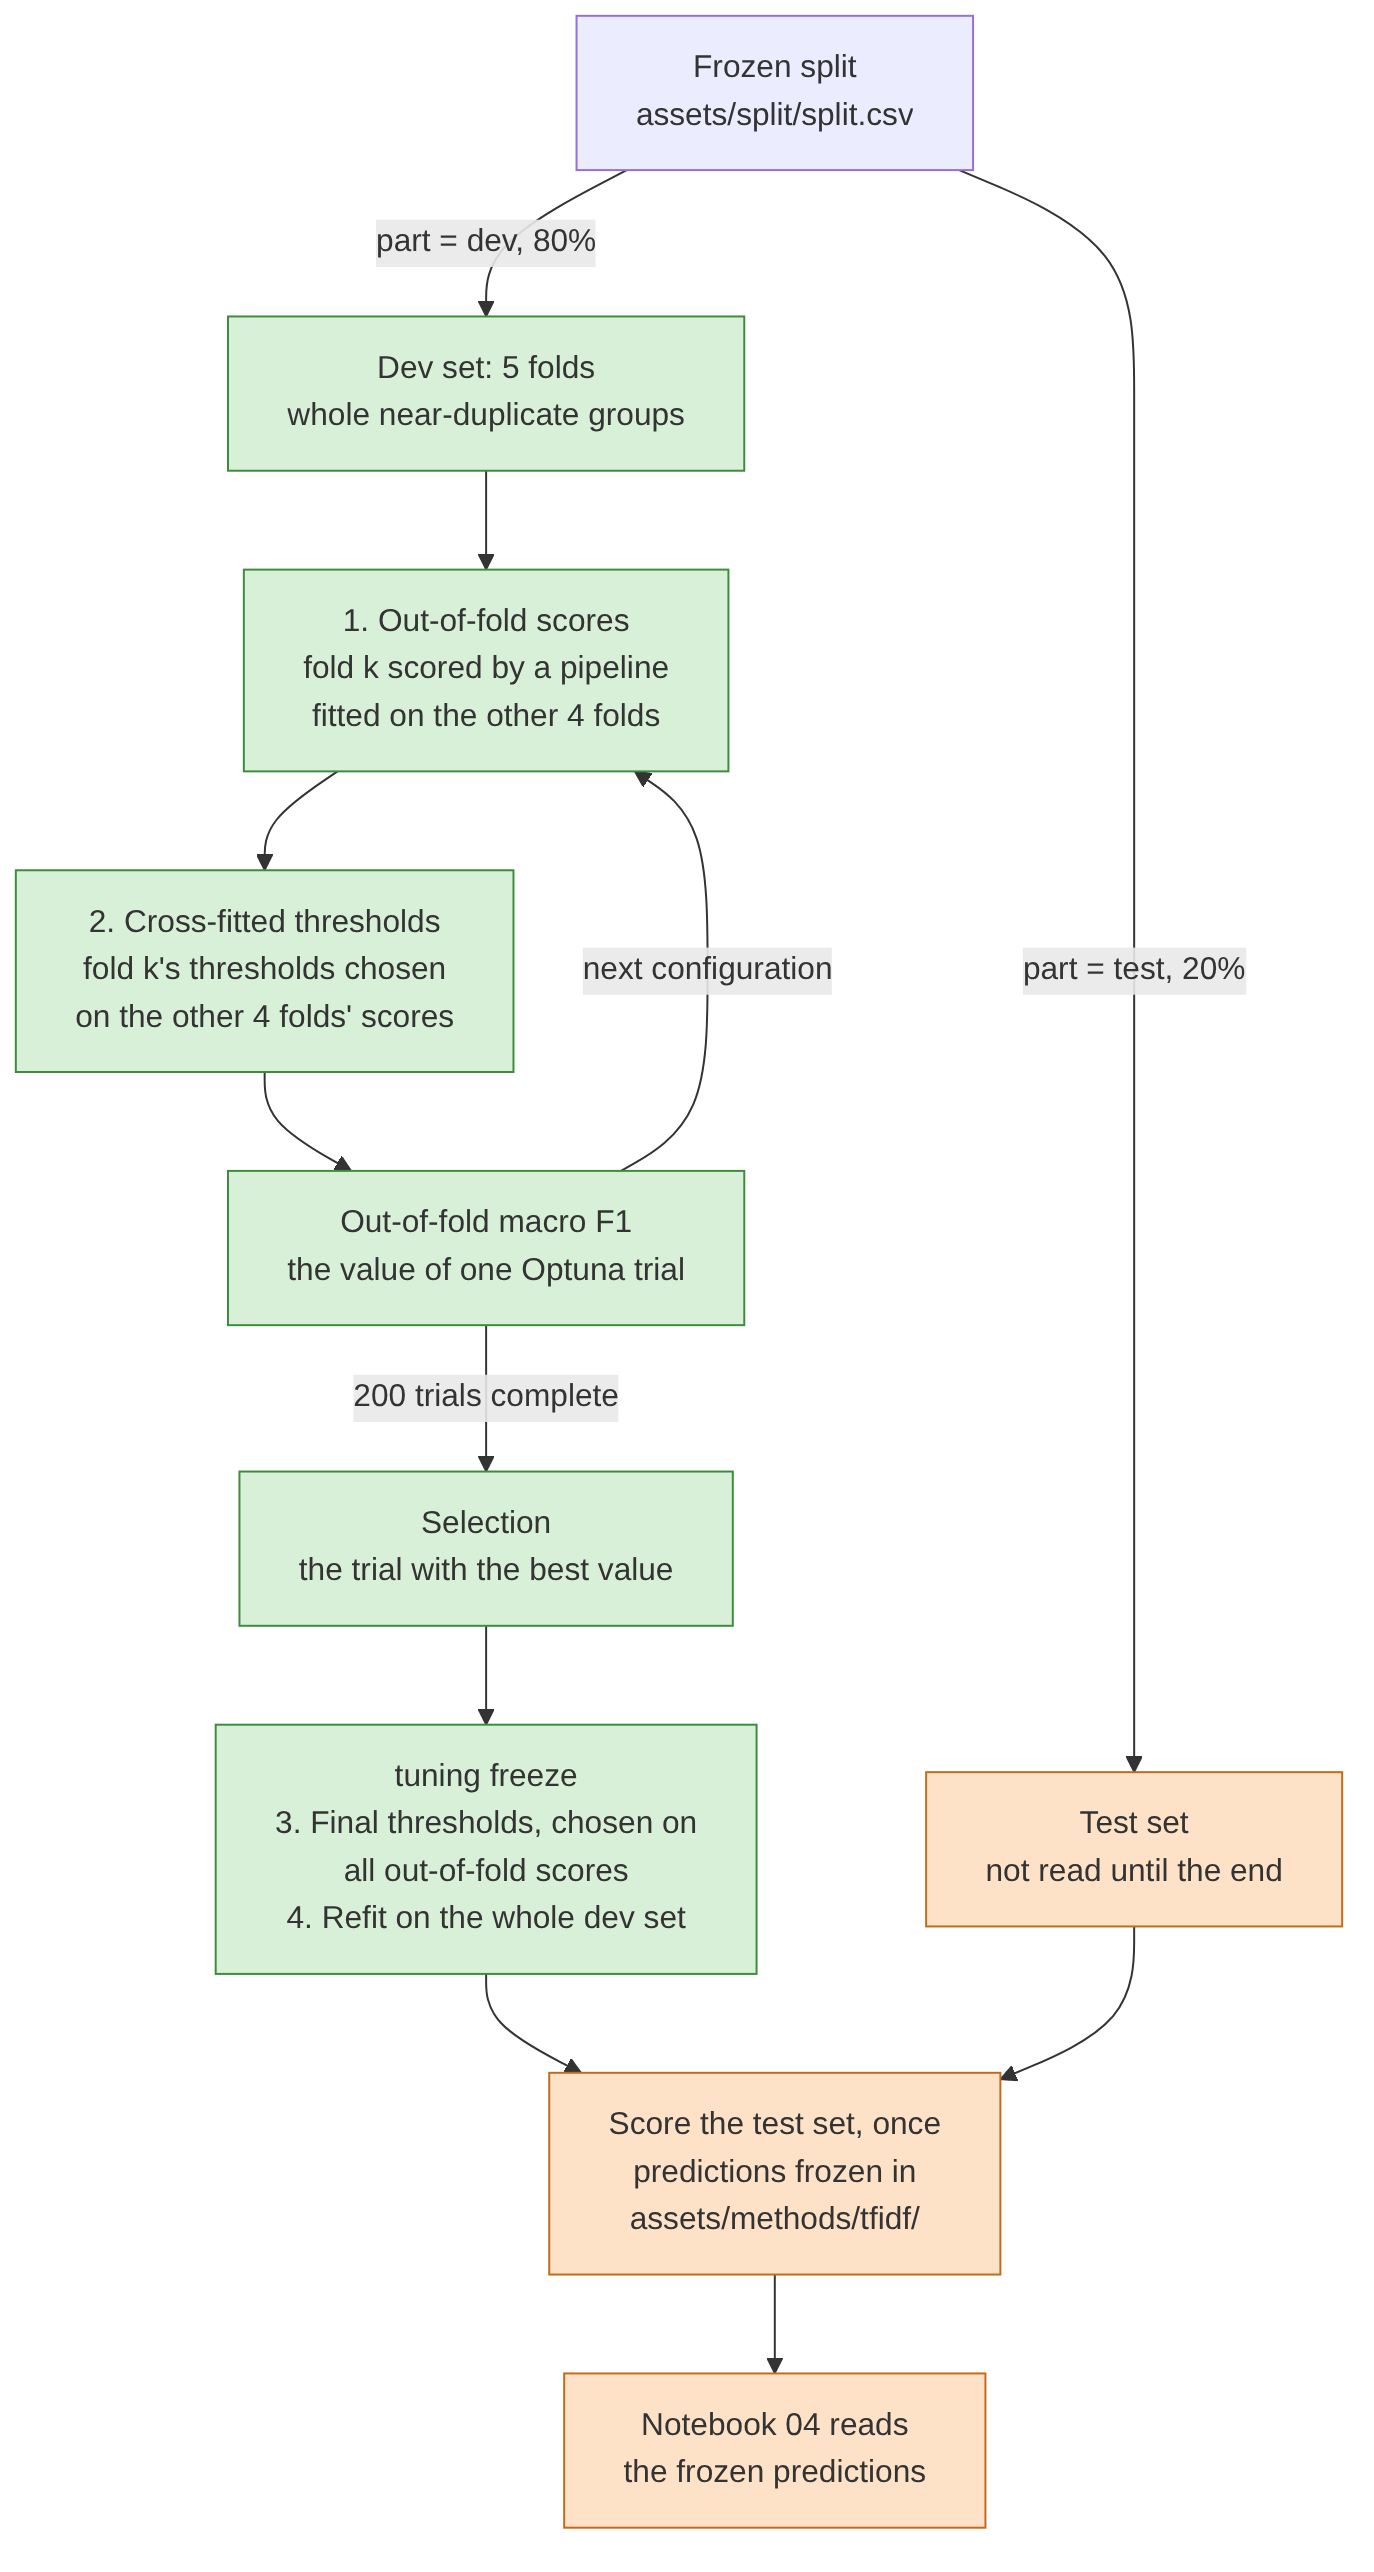

In [1]:
from IPython.display import Image

Image(filename="figures/tfidf_protocol.png", width=440)

In [2]:
import textwrap
import time
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import f1_score

from codeforces_tags.analysis.eda import lift
from codeforces_tags.analysis.error_analysis import misclassified
from codeforces_tags.analysis.pipeline_trace import parameter_table, trace_problem
from codeforces_tags.analysis.plotting import (
    plot_confusion_grid,
    plot_intervals,
    plot_reliability,
    plot_reliability_grid,
    plot_study_history,
    plot_tag_confusion,
    setup_style,
)
from codeforces_tags.config import (
    ABLATIONS,
    ERROR_EXCERPT_CHARS,
    FOCUS_COLOR,
    FOCUS_TAGS,
    RELEASE_ERA_FIRST_YEAR,
    TERMS_TOP_K,
    TFIDF_TEST_MACRO_F1,
    TUNING_EXPORT_TOLERANCE,
    TUNING_STARTUP_TRIALS,
)
from codeforces_tags.data.labels import focus_labels, multi_hot
from codeforces_tags.data.loading import read_samples
from codeforces_tags.evaluation.calibration import (
    POOLED,
    calibration_table,
    lipton_table,
    mapped_predictions,
    platt_maps,
    probabilities_by_method,
)
from codeforces_tags.evaluation.predictions import load_predictions
from codeforces_tags.evaluation.report import (
    ALL_PROBLEMS,
    EARLY_ERA,
    LATE_ERA,
    compare,
    evaluate,
)
from codeforces_tags.methods import load_method, method_dir, model_dir
from codeforces_tags.model.features import (
    SAMPLE_IO_CUES,
    code_tokens,
    normalise_statement,
    sample_io_cues,
)
from codeforces_tags.model.first_look import first_look_pipeline
from codeforces_tags.model.thresholds import (
    CrossFittedTagThresholds,
    apply_thresholds,
    per_tag_thresholds,
)
from codeforces_tags.model.training import build_pipeline, cross_fit
from codeforces_tags.preprocessing.pipeline import preprocess
from codeforces_tags.splitting import load_split, release_years, select_part
from codeforces_tags.tuning.results import load_tuning_results

setup_style()
pd.set_option("display.max_colwidth", 110)

# The models read the raw problems, as read_samples() gives them, and preprocess them
# themselves; the statistics and the error analysis read the preprocessed ones.
raw = read_samples()
df = preprocess(raw)
split = load_split()
dev_raw = select_part(raw, split, "dev")
dev = select_part(df, split, "dev")
assert dev_raw.index.equals(dev.index), "the raw and preprocessed dev problems differ"
labels = focus_labels(dev)
years = release_years(dev)
results = load_tuning_results()
print(
    f"dev set: {len(dev):,} problems, {dev['group'].nunique():,} near-duplicate groups, "
    f"{dev['fold'].nunique()} folds"
)

dev set: 3,988 problems, 3,919 near-duplicate groups, 5 folds


## 1. A first look: one logistic regression on every tag

The task ([`PROBLEM.md`](../PROBLEM.md)) focuses on 8 tags because the others are hard to
predict and noisily labelled. Before narrowing down, this section measures that with
the simplest model, fitted on **every** tag of the dev set, the 8 focus tags and the others
alike:
`first_look_pipeline()` (in `codeforces_tags.model.first_look`). Like the tuned model, it
reads raw problems and preprocesses them itself; then it reads the statement only (TF-IDF of
words and word pairs, after the statement normaliser of section 2) and fits one logistic
regression per tag (one-vs-rest).

**Thresholds cross-fitted on the dev folds.** A tag is predicted when its score reaches the
tag's threshold, cross-fitted as for the tuned model
([ADR 0001](../docs/adr/0001-model-selection-protocol.md)): fold k's threshold is the one
that maximises the tag's F1 on the other four folds' out-of-fold scores, so no fold is
scored with a threshold fitted to it. For comparison, the tables also show scikit-learn's
default, a probability above 0.5.

Nothing here is tuned, and the test set is not used: `cross_fit()` scores each dev problem
with a pipeline fitted on the four frozen folds that do not hold it (the split's `fold`), so
the two versions of a problem never sit on both sides, then predicts it with the thresholds
of its fold. The cell fails unless the focus tags' macro F1 is exactly 0.6120022337298635,
the value the conclusions below were drawn from.

In [3]:
all_tags = multi_hot(dev_raw["tags"])
is_focus = all_tags.columns.isin(FOCUS_TAGS)
print(f"{all_tags.shape[1]} tags: {is_focus.sum()} focus tags and {(~is_focus).sum()} others")
says_interactive = dev["statement"].str.contains("interactive problem", case=False, regex=False)
interactive = all_tags["interactive"].eq(1)
print(
    f'"interactive problem" is in {(says_interactive & interactive).sum()} of the '
    f"{interactive.sum()} interactive statements, "
    f"and in {(says_interactive & ~interactive).sum()} others"
)

37 tags: 8 focus tags and 29 others
"interactive problem" is in 78 of the 102 interactive statements, and in 0 others


In [4]:
first_look = cross_fit(first_look_pipeline(), dev_raw, all_tags, dev_raw["fold"])
first_look_predictions = {
    # A logistic regression's probability is above 0.5 exactly when its score is above 0.
    "0.5 probability": (first_look.scores > 0).astype(int),
    "cross-fitted thresholds": first_look.predictions,
}
first_look_macro_f1 = pd.DataFrame(
    {
        name: {
            f"focus tags ({is_focus.sum()})": f1_score(
                all_tags.loc[:, is_focus],
                predicted.loc[:, is_focus],
                average="macro",
                zero_division=0,
            ),
            f"other tags ({(~is_focus).sum()})": f1_score(
                all_tags.loc[:, ~is_focus],
                predicted.loc[:, ~is_focus],
                average="macro",
                zero_division=0,
            ),
            f"all tags ({all_tags.shape[1]})": f1_score(
                all_tags, predicted, average="macro", zero_division=0
            ),
        }
        for name, predicted in first_look_predictions.items()
    }
)
focus_row = f"focus tags ({is_focus.sum()})"
first_look_focus_f1 = first_look_macro_f1.at[focus_row, "cross-fitted thresholds"]
assert first_look_focus_f1 == 0.6120022337298635, f"{first_look_focus_f1!r} != 0.6120022337298635"
print("Macro F1, out of fold:")
display(first_look_macro_f1.round(3))
first_look_f1 = pd.DataFrame(
    {
        "kind": ["focus" if focus else "other" for focus in is_focus],
        "dev problems": all_tags.sum(),
    }
    | {
        f"F1, {name}": f1_score(all_tags, predicted, average=None, zero_division=0)
        for name, predicted in first_look_predictions.items()
    },
    index=all_tags.columns,
)
first_look_f1.sort_values("F1, cross-fitted thresholds", ascending=False).round(3)

Macro F1, out of fold:


,0.5 probability,cross-fitted thresholds
focus tags (8),0.189,0.612
other tags (29),0.034,0.260
all tags (37),0.067,0.336


,kind,dev problems,"F1, 0.5 probability","F1, cross-fitted thresholds"
label,,,,
interactive,other,102,0.000,0.912
games,focus,84,0.024,0.739
strings,focus,337,0.429,0.699
probabilities,focus,74,0.000,0.629
greedy,other,1414,0.415,0.625
trees,focus,261,0.373,0.622
geometry,focus,133,0.015,0.602
graphs,focus,434,0.348,0.577
math,focus,1127,0.298,0.573


**What it shows** (thresholds cross-fitted on the dev folds, unless said otherwise):
- **The focus tags are the easier ones.** Their macro F1 is 0.612, against 0.260 for the 29
  other tags and 0.336 over all 37. All 8 focus tags rank in the top 14 of the 37, from `games` (0.739) to
  `number theory` (0.455). Only 6 of the 29 others reach 0.455, led by `interactive`
  (0.912): 78 of its 102 dev statements say "interactive problem", and no other statement
  does.
- **Most of the gap is rarity.** The 11 other tags with an F1 below 0.1 all have at most 35
  dev problems: too few positives to learn from, and each weighs as much as `greedy` in the
  macro F1.
- **Technique tags are hard to read from the statement.** `dp` (0.447), `sortings` (0.384),
  `brute force` (0.306), `binary search` (0.297) and `two pointers` (0.213) name how a
  problem is solved, which the statement rarely says.
- **Cross-fitted thresholds matter.** At scikit-learn's default probability of 0.5,
  the macro F1 falls to 0.189 for the focus tags, 0.034 for the others and 0.067 over all
  tags. Every tag is held by a minority of problems, so a logistic regression seldom gives
  one a probability above 0.5: `probabilities` and 22 of the other tags get an F1 of 0.000,
  rare ones such as `interactive` (102 dev problems) but also frequent ones such as
  `brute force` (661) and `sortings` (547).
- **For context, the paper's Python baseline.** The xCodeEval paper's only tag classifier
  is `gpt-3.5-turbo`, asked zero-shot (p.6, Table 3). For Python, it scores a macro F1 of
  0.295 from the solution alone and 0.337 from the description and the solution (29.45 and
  33.73 in the paper's percent), over its own tag set of about 31 tags, on its validation
  split. This untuned logistic regression scores 0.336 over our 37 tags, out of fold. The
  two are context, not a leaderboard: the tag sets, the splits and the number of solutions
  per problem differ, the paper reports one run with no interval, and the LLM may have seen
  these problems in training
  ([paper notes](../docs/xcodeeval-paper-notes.md), sections 5 and 8).

The tuned model of the next sections also reads the solution and the notes, and reaches a
macro F1 of 0.663 on the focus tags (section 4).

## 2. What the tuned model reads

Three feature blocks, each built from one input of a problem, put side by side in one
sparse matrix (`feature_blocks()` in `codeforces_tags.model.features`):

| Block | Input | Features | Weight |
|---|---|---|---|
| **statement** | the statement (description, input and output specifications), followed by the notes when `include_notes` is set | TF-IDF of word n-grams, after a normaliser for LaTeX and HTML | 1 |
| **code** | the solution | TF-IDF of code-token n-grams | `code_weight`, tuned |
| **cues** | the sample inputs and outputs | 5 yes/no sample I/O cues | `cue_weight`, tuned; the study can drop the block |

Left out on purpose:
- **the difficulty rating**, set after the contest, so unknown for a new problem;
- **the release date, the Python version and the `$$$` delimiters**: they tell the release
  era, along which the tag mix drifts, not what the problem is about;
- **the time and memory limits**: their medians are the same for every focus tag
  (notebook 01, section 6);
- **the hidden tests**, always empty.

**The statement normaliser.** Statements from 2018 on write their math in `$$$` LaTeX,
older ones in flattened Unicode, where the scraper turned 10<sup>9</sup> into `109`.
`normalise_statement()` makes one idea one word in both: `\le`, `\leq` and `≤` all become
`le`; the moduli 998244353 and 10^9 + 7 become `mod998244353` and `mod1e9p7` in every
spelling; `10^5` becomes `1e5`; HTML entities are unescaped; the text is lowercased.
Flattened powers stay as they are: `105` cannot be told apart from the number 105. The
input and output specifications of three dev problems, where most of the math is, before
and after:

In [5]:
late = years >= RELEASE_ERA_FIRST_YEAR
specs = dev["prob_desc_input_spec"].fillna("") + "\n\n" + dev["prob_desc_output_spec"].fillna("")
examples = {
    f"from {RELEASE_ERA_FIRST_YEAR}, $$$ LaTeX": late & specs.str.contains("998244353"),
    f"up to {RELEASE_ERA_FIRST_YEAR - 1}, flattened": ~late & specs.str.contains("1000000007"),
    "HTML entities": specs.str.contains("&lt;"),
}
for name, found in examples.items():
    sample_id = specs[found].index[0]
    print(f"Problem {sample_id} ({name}; released {years[sample_id]}), before:")
    print(textwrap.fill(specs[sample_id], 100))
    print("After:")
    print(textwrap.fill(normalise_statement(specs[sample_id]), 100), end="\n\n")

Problem 51 (from 2018, $$$ LaTeX; released 2019), before:
The first line of the input contains one integer $$$n$$$ ($$$1 \le n \le 2 \cdot 10^5$$$) — the
number of elements in $$$a$$$ and $$$b$$$. The second line of the input contains $$$n$$$ integers
$$$a_1, a_2, \dots, a_n$$$ ($$$1 \le a_i \le 10^6$$$), where $$$a_i$$$ is the $$$i$$$-th element of
$$$a$$$. The third line of the input contains $$$n$$$ integers $$$b_1, b_2, \dots, b_n$$$ ($$$1 \le
b_j \le 10^6$$$), where $$$b_j$$$ is the $$$j$$$-th element of $$$b$$$.  Print one integer — the
minimum possible value of $$$\sum\limits_{1 \le l \le r \le n} f(l, r)$$$ after rearranging elements
of $$$b$$$, taken modulo $$$998244353$$$. Note that you should minimize the answer but not its
remainder.
After:
the first line of the input contains one integer n ( 1 le n le 2 cdot 1e5 ) — the number of elements
in a and b . the second line of the input contains n integers a_1, a_2, dots , a_n ( 1 le a_i le 1e6
), where a_i is the i -th element o

- **One word per idea, in both eras.** `\le` (2019) and `≤` (2016) both give `le`, and
  `\dots` gives `dots`. Without the normaliser, the TF-IDF would hold `le` and `≤` as two
  words, each frequent in one era only, and a tag's words would differ with the era.
- **The moduli become words.** `998244353` and `1000000007 (109 + 7)` become
  `mod998244353` and `mod1e9p7`. Notebook 01 (section 7.4) names the modulus 998244353
  among the strongest cues of the math spans, for `probabilities`.
- **Flattened powers stay.** In the 2016 problem, `- 109 ≤ li ≤ ri ≤ 109` means ±10^9, but
  a rule that rebuilt it would also turn real numbers such as 105 into 10^5.

The TF-IDF then keeps the words of two or more letters, digits or underscores, so
one-letter variables (`n`, `a`) and the math operators drop out.

**The code block** lowercases the solution and keeps every run of two or more letters,
digits or underscores, comments and string literals included (`code_tokens()`). Nothing is
parsed, so Python 2 and Python 3 solutions give the same kind of tokens. The moduli get
the statement's words. A short dev solution and its tokens:

In [6]:
short = dev["source_code"].str.count("\n") < 10
solution = dev.loc[short & dev["source_code"].str.contains(r"10\s*\*\*\s*9"), "source_code"].iloc[0]
print(solution)
print("code_tokens():")
print(textwrap.fill(" ".join(code_tokens(solution)), 100))

from math import factorial as fact
mod = 10**9 + 7

def Ct(n, k):
	return fact(n) // (fact(k) * fact(n - k))
n, m = map(int, input().split())
print(Ct(n + 2*m - 1, 2*m) % mod)
code_tokens():
from math import factorial as fact mod mod1e9p7 def ct return fact fact fact map int input split
print ct mod


`10**9 + 7` gives `mod1e9p7`, the word the statement's `10^9 + 7` gives, and one-letter
names drop out.

**The sample I/O cues** are five yes/no facts read from a problem's sample inputs and
outputs (`sample_io_cues()`), each meant for one or two of the rare tags:

| Cue | Fires when | Meant for |
|---|---|---|
| `tree_edge_list` | a sample input holds a number n ≥ 4, then n − 1 lines of edges that join the n nodes without a cycle (checked by union-find) | `trees` |
| `graph_edge_list` | a sample input holds a line "n m", then m lines of edges between nodes 1 to n | `graphs` |
| `decimal_output` | a sample output holds a decimal number | `geometry`, `probabilities` |
| `letters_output` | every sample output line is letters and spaces, and not all of them are YES or NO | `strings`, `games` |
| `player_output` | a sample output names a player or an outcome: Alice, Bob, First, Second, Draw, Win, Lose… | `games` |

A problem without samples gets 0 for every cue. Their lift on the dev set: how many times
more frequent a tag is among the problems where the cue fires than among all dev problems
(1: no association; `problems`: the dev problems where it fires):

In [7]:
cues = pd.DataFrame(sample_io_cues(dev), index=dev.index, columns=list(SAMPLE_IO_CUES))
cue_lift = lift(cues.astype(int), labels)
cue_lift.insert(0, "problems", cues.sum().astype(int))
cue_lift.round(2)

label,problems,math,graphs,strings,number theory,trees,geometry,games,probabilities
tree_edge_list,269,0.43,4.82,0.09,0.43,6.87,0.45,0.71,0.80
graph_edge_list,547,0.74,2.82,0.19,0.55,2.43,1.32,1.13,0.69
decimal_output,120,1.59,0.31,0.30,0.00,0.76,10.24,0.40,12.57
letters_output,183,0.56,0.85,4.27,0.55,0.42,0.33,8.56,0.29
player_output,29,0.98,0.63,2.45,0.99,0.53,0.00,29.47,0.00


Each cue raises the chance of the tag it was meant for, several times over: `player_output`
makes `games` 29 times as frequent (18 of its 29 problems are `games`), `decimal_output`
makes `geometry` and `probabilities` 10 and 13 times as frequent, and `tree_edge_list`
makes `trees` 7 times as frequent. The cues are strongly associated with their tags, but
rare: `tree_edge_list` fires on under half of the `trees` problems, `player_output` on a
fifth of the `games` ones. Whether the model needs them on top of the words is the study's
question (`use_cues`), and the ablations' (section 4).

**The pipeline, in one scikit-learn object.** The tag model reads raw problems, as
`read_samples()` gives them, and returns one score per focus tag. `build_pipeline(params)`
chains three steps: `preprocess` (`raw_to_problems`, the preprocessing of `load_dataset()`,
so a new problem needs no separate step), `features` (the blocks above, side by side, each
with its weight) and `classifier` (one linear model per tag, `OneVsRestClassifier`).
scikit-learn's own diagram of it, for the chosen configuration of section 3 (`params.json`),
rendered by `figures/estimator_diagram.py`:

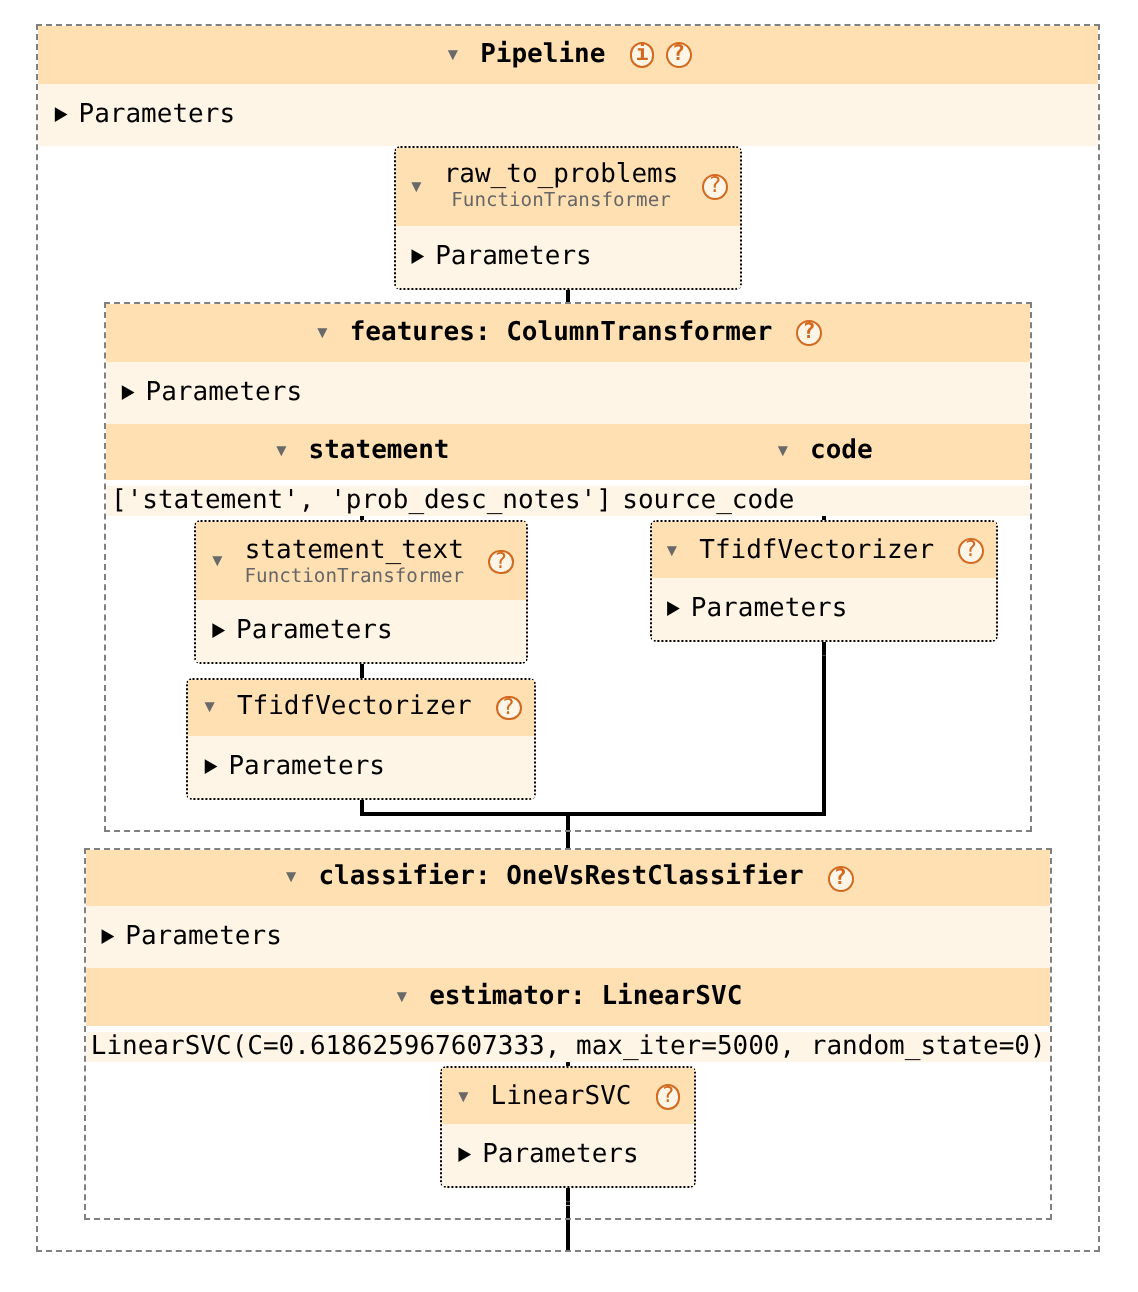

In [8]:
Image(filename="figures/tfidf_estimator.png", width=560)

The diagram shows the steps, not how they are fitted. One more object,
`CrossFittedTagThresholds`, wraps the pipeline and fits it under the protocol of
[ADR 0001](../docs/adr/0001-model-selection-protocol.md): it scores each dev problem with a
clone of the pipeline fitted on the four folds that do not hold it, chooses each fold's
thresholds on the other folds' scores, then the final thresholds on all of them, and refits
the pipeline on the whole dev set. `cross_fit()` stops before the refit: it gives the
out-of-fold predictions, whose macro F1 is a trial's value in section 3, and the final
thresholds, which section 4 compares with `thresholds.json`. `fit_tag_model()` goes on to
the refit, and gives the tag model of section 4. The cue block is drawn, though the chosen
configuration does not keep it (source: `figures/tfidf_pipeline.mmd`):

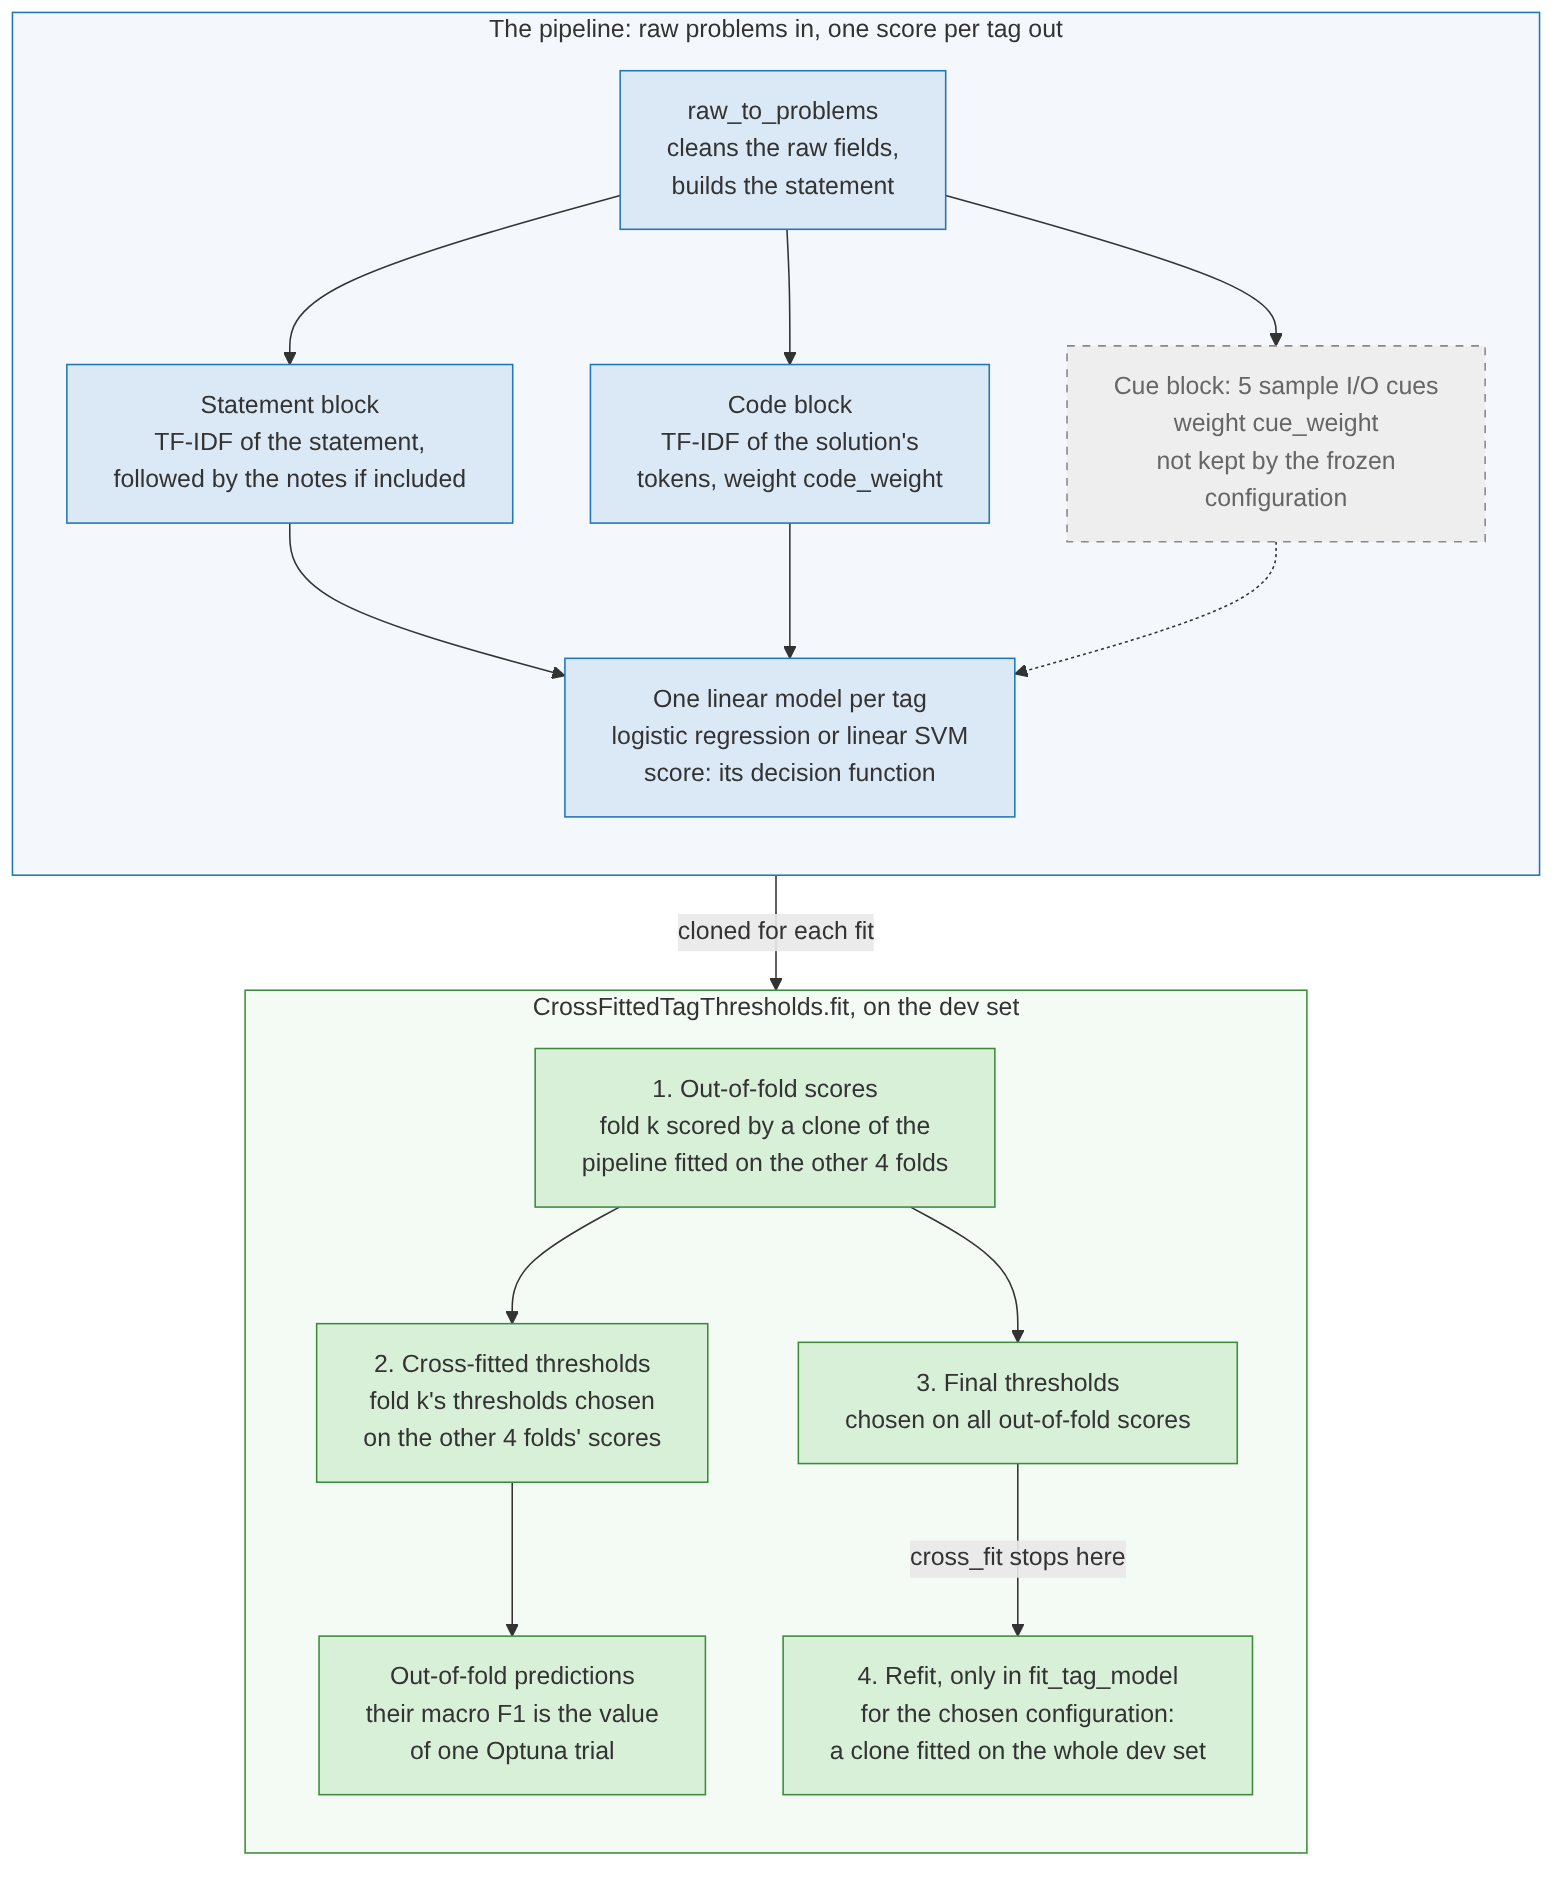

In [9]:
Image(filename="figures/tfidf_pipeline.png", width=700)

**Where each setting goes.** Each field of the chosen configuration, its value, and the
parameter it sets on the tag model's `CrossFittedTagThresholds` (the object that
`load_method()` returns inside the tag model, section 4), named as `set_params()` names it
(`parameter_table()` in `codeforces_tags.analysis.pipeline_trace`). `code_weight` and
`cue_weight` both go into `transformer_weights`, the weight of each block, and `blocks`
chooses the transformers themselves, so the settings of a block that is not kept set
nothing:

In [10]:
parameter_table(results.params)

,value,sets
parameter,,
classifier,linear_svm,estimator__classifier__estimator
c,0.618626,estimator__classifier__estimator__C
class_weight,none,estimator__classifier__estimator__class_weight
include_notes,True,estimator__features__statement__text__kw_args
statement_ngram_max,2,estimator__features__statement__tfidf__ngram_range
statement_min_df,3,estimator__features__statement__tfidf__min_df
statement_max_df,0.623211,estimator__features__statement__tfidf__max_df
statement_sublinear_tf,True,estimator__features__statement__tfidf__sublinear_tf
code_weight,0.223986,estimator__features__transformer_weights


## 3. Choosing its configuration: the Optuna study

The configuration was chosen by an Optuna study: a multivariate TPE sampler after 30 random
trials, with 4 worker processes sharing one journal. `suggest_params()` in
`codeforces_tags.tuning.search` draws each configuration: the classifier (logistic
regression or linear SVM) and its C, the class weighting, whether the notes are read, the
TF-IDF settings of both text blocks, the code block's weight, and whether the cue block is
kept, with its weight. [`assets/tfidf_baseline/README.md`](../assets/tfidf_baseline/README.md)
lists the ranges. The value of each trial, and the best value so far:

203 complete trials of 203; best: trial 185, out-of-fold macro F1 0.6629


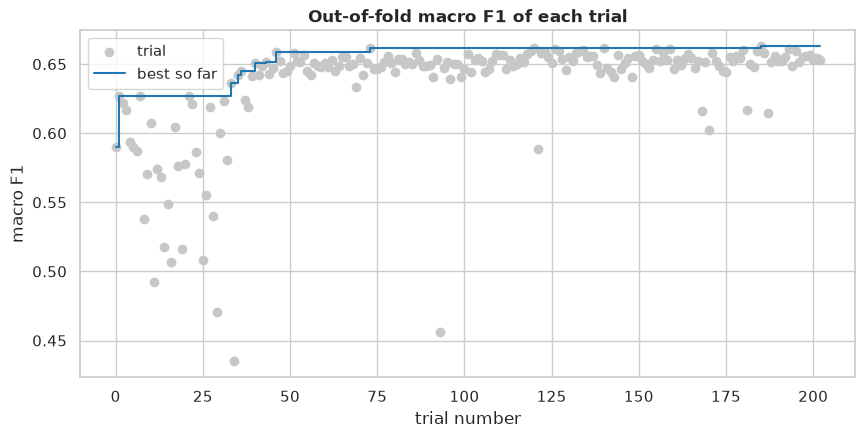

In [11]:
complete = results.trials[results.trials["state"] == "COMPLETE"]
best_trial = complete.loc[complete["value"].idxmax()]
print(
    f"{len(complete)} complete trials of {len(results.trials)}; best: trial "
    f"{best_trial['number']}, out-of-fold macro F1 {best_trial['value']:.4f}"
)
ax = plot_study_history(results.trials)
ax.set(title="Out-of-fold macro F1 of each trial", ylabel="macro F1")
plt.show()

**Which parameters matter.** The fANOVA importance of a parameter is its share of the
variance of the macro F1 across trials that single parameters explain (Optuna's
`FanovaImportanceEvaluator`: each parameter's main effect, normalised so that the
importances sum to 1; the interactions between parameters are left out). The C of each
classifier and the cue weight are left out too, since not every trial draws them:

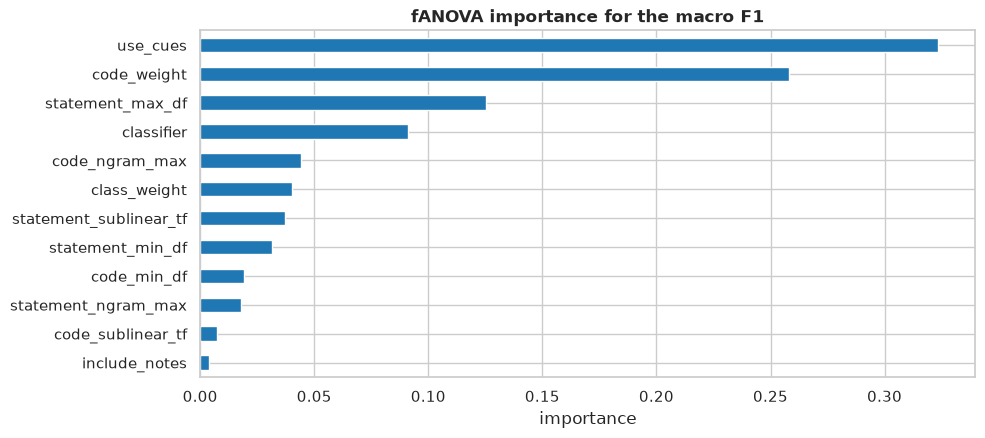

In [12]:
ax = results.importances.sort_values().plot.barh(color=FOCUS_COLOR)
ax.set(title="fANOVA importance for the macro F1", xlabel="importance", ylabel="")
plt.show()

**The chosen configuration**, as saved in `params.json`: `c` is the C of the chosen
classifier, `cue_weight` is 0 when the cue block is dropped, and `blocks` lists the blocks
kept. The table of section 2 gives the parameter of the pipeline that each one sets.

In [13]:
pd.Series(results.params.to_dict(), name="value").to_frame()

,value
classifier,linear_svm
c,0.618626
class_weight,none
include_notes,True
statement_ngram_max,2
statement_min_df,3
statement_max_df,0.623211
statement_sublinear_tf,True
code_weight,0.223986
code_ngram_max,1


**The choices, one at a time.** For each categorical or yes/no parameter, the complete
trials that made each choice, their best value and their median. The best value compares
the options at their best settings. The median is blurred by the other parameters, which
change from trial to trial, and TPE draws more trials where it expects good values, so the
counts are not balanced either. Below the table: how many of the cue trials were among the
first 30, the random startup trials, and the five best trials.

In [14]:
choices = ["classifier", "class_weight", "include_notes", "use_cues"]
display(
    pd.concat(
        {
            choice: complete.groupby(f"params_{choice}")["value"].agg(["count", "max", "median"])
            for choice in choices
        },
        names=["parameter", "option"],
    )
    .rename(columns={"count": "trials", "max": "best"})
    .round(4)
)
first = complete["number"] < TUNING_STARTUP_TRIALS
cues_kept = complete["params_use_cues"].eq(True)
print(
    f"cue block kept in {cues_kept[first].sum()} of the first {first.sum()} trials, "
    f"and in {cues_kept[~first].sum()} of the {(~first).sum()} that followed"
)
print("The five best trials:")
trial_columns = [
    "value",
    "params_classifier",
    "params_class_weight",
    "params_use_cues",
    "params_include_notes",
]
display(complete.nlargest(5, "value").set_index("number")[trial_columns].round(4))

trials    best  median
parameter     option                                     
classifier    linear_svm              186  0.6629  0.6510
              logistic_regression      17  0.6270  0.5705
class_weight  balanced                 19  0.6445  0.5806
              none                    184  0.6629  0.6510
include_notes False                    16  0.6561  0.5969
              True                    187  0.6629  0.6508
use_cues      False                   177  0.6629  0.6513
              True                     26  0.6479  0.5736

cue block kept in 22 of the first 30 trials, and in 4 of the 173 that followed
The five best trials:


,value,params_classifier,params_class_weight,params_use_cues,params_include_notes
number,,,,,
185,0.6629,linear_svm,none,False,True
140,0.6616,linear_svm,none,False,True
120,0.6615,linear_svm,none,False,True
73,0.6614,linear_svm,none,False,True
193,0.6612,linear_svm,none,False,True


## 4. The chosen model on the dev set, out of fold

`cross_fit()` fits the chosen configuration's pipeline (`build_pipeline(params)`, on the raw
dev problems) on four folds and scores the fifth, for each fold in turn, then predicts each
fold with the thresholds chosen on the other four folds' scores. That is the study's
objective, so its macro F1 must equal the frozen value of `out_of_fold.csv`, and its final
thresholds, chosen on all the out-of-fold scores, those of `thresholds.json` to within
`TUNING_EXPORT_TOLERANCE` (1e-9): the cell fails otherwise.

`evaluate()` then scores the predictions on four slices of the dev set: all problems, the
focus-tagged ones, and the two release eras. On the focus-tagged slice, the no-focus
problems (46% of the dev set) and their false positives are left out, so the gap with all
problems is what the no-focus problems cost. `_low` and `_high` bound the 95% intervals.
`no_focus_nothing_predicted` is the share of the no-focus problems that get no tag at all.

In [15]:
out_of_fold = cross_fit(build_pipeline(results.params), dev_raw, labels, dev_raw["fold"])
oof = evaluate(labels, out_of_fold.predictions, release_years=years, groups=dev["group"])
frozen_macro_f1 = results.out_of_fold.at["macro_f1", "f1"]
assert oof.macro_f1 == frozen_macro_f1, f"{oof.macro_f1} != {frozen_macro_f1} (out_of_fold.csv)"
pd.testing.assert_series_equal(
    out_of_fold.thresholds,
    results.thresholds,
    check_exact=False,
    rtol=0,
    atol=TUNING_EXPORT_TOLERANCE,
    check_names=False,
    check_index_type=False,
)
print(f"out-of-fold macro F1 {oof.macro_f1:.4f}, as in out_of_fold.csv")
summary_columns = [
    "problems",
    "macro_f1",
    "macro_f1_low",
    "macro_f1_high",
    "micro_f1",
    "micro_f1_low",
    "micro_f1_high",
    "no_focus_nothing_predicted",
]
oof.summary[summary_columns].round(3)

out-of-fold macro F1 0.6629, as in out_of_fold.csv


,problems,macro_f1,macro_f1_low,macro_f1_high,micro_f1,micro_f1_low,micro_f1_high,no_focus_nothing_predicted
slice,,,,,,,,
all problems,3988,0.663,0.642,0.683,0.617,0.604,0.632,0.531
focus-tagged,2143,0.729,0.709,0.749,0.731,0.718,0.745,NaN
up to 2017,1626,0.662,0.628,0.692,0.587,0.562,0.613,0.650
from 2018,2362,0.653,0.623,0.679,0.633,0.615,0.650,0.421


**Per tag**, over all dev problems: precision, recall and F1, the interval of F1, and the
final threshold. A threshold is on the scale of the model's scores (`decision_function`: a
margin for the linear SVM, a logit for logistic regression), and a tag is predicted when
its score reaches it. The dashed line is the macro F1.

,support,precision,recall,f1,f1_low,f1_high,threshold
tag,,,,,,,
math,1127,0.477,0.745,0.582,0.560,0.604,-0.420
graphs,434,0.602,0.604,0.603,0.563,0.639,-0.455
strings,337,0.652,0.733,0.690,0.652,0.730,-0.286
number theory,278,0.595,0.496,0.541,0.487,0.595,-0.447
trees,261,0.774,0.670,0.719,0.668,0.766,-0.357
geometry,133,0.656,0.647,0.652,0.581,0.715,-0.390
games,84,0.892,0.786,0.835,0.765,0.891,-0.319
probabilities,74,0.776,0.608,0.682,0.582,0.772,-0.618


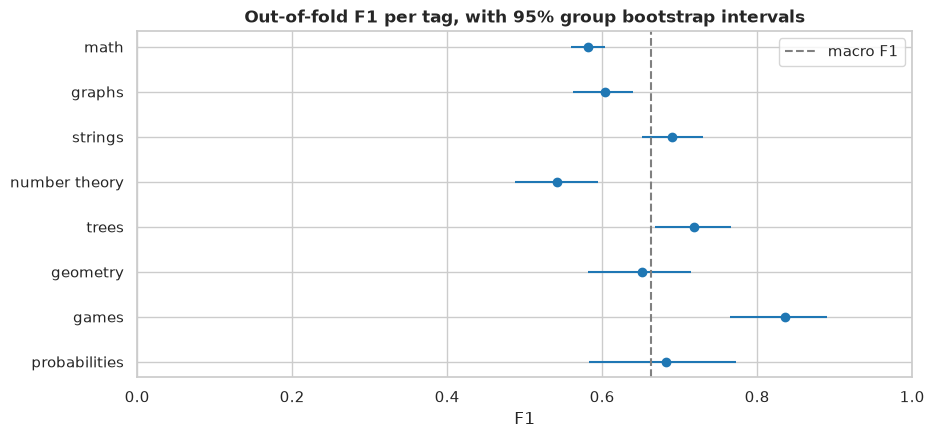

In [16]:
per_tag = oof.per_tag.loc[ALL_PROBLEMS].assign(threshold=out_of_fold.thresholds)
per_tag_columns = ["support", "precision", "recall", "f1", "f1_low", "f1_high", "threshold"]
display(per_tag[per_tag_columns].round(3))
ax = plot_intervals(per_tag, "f1", "f1_low", "f1_high")
ax.axvline(oof.macro_f1, color="grey", linestyle="--", label="macro F1")
ax.set(title="Out-of-fold F1 per tag, with 95% group bootstrap intervals", xlabel="F1", xlim=(0, 1))
ax.legend()
plt.show()

`probabilities`, the rarest tag (74 dev problems), has the widest interval, then `geometry`
(133) and `games` (84): one problem more or less moves a rare tag's F1 the most, and the high
F1 of `games` narrows its interval. A few points of F1 between two rare tags is within the
noise.

**Why the thresholds are cross-fitted.** A threshold chosen on all the out-of-fold scores,
then scored on the predictions it gives on those same scores, is fitted to the problems it
is scored on ([ADR 0001](../docs/adr/0001-model-selection-protocol.md)). The next cell
measures how much that would flatter the chosen configuration: the final thresholds of
`thresholds.json` applied to all its out-of-fold scores ("pooled"), against the
cross-fitted predictions above. The difference is paired: both are scored on the same
bootstrap resamples, so its interval leaves out how hard the drawn problems are. A
difference whose interval excludes 0 is more than resampling noise.

In [17]:
pooled = apply_thresholds(out_of_fold.scores, out_of_fold.thresholds)
pooled_gap = compare(labels, out_of_fold.predictions, pooled, dev["group"])
print(
    "macro F1 with thresholds chosen on, and applied to, all out-of-fold scores: "
    f"{pooled_gap.at['macro_f1', 'candidate']:.4f}, against {oof.macro_f1:.4f} cross-fitted"
)
pooled_gap.rename(columns={"baseline": "cross-fitted", "candidate": "pooled"}).round(3)

macro F1 with thresholds chosen on, and applied to, all out-of-fold scores: 0.6691, against 0.6629 cross-fitted


,cross-fitted,pooled,delta,delta_low,delta_high
metric,,,,,
macro_f1,0.663,0.669,0.006,0.002,0.011
micro_f1,0.617,0.622,0.005,0.002,0.007
math,0.582,0.583,0.001,0.000,0.002
graphs,0.603,0.611,0.008,-0.001,0.018
strings,0.690,0.698,0.008,0.002,0.017
number theory,0.541,0.547,0.006,-0.005,0.017
trees,0.719,0.723,0.004,0.000,0.011
geometry,0.652,0.659,0.008,0.000,0.021
games,0.835,0.835,0.000,0.000,0.000


Pooled thresholds score 0.669 against 0.663 cross-fitted, a paired difference of +0.006
[0.002, 0.011]: the optimism that the study avoids by maximising the cross-fitted score. Per
tag, the gap is largest on `probabilities`, the rarest tag (+0.014), but its interval
includes 0.

**What each feature block adds.** The chosen configuration is cross-fitted again with the
feature blocks of each ablation (`ABLATIONS` in `config.py`: all three blocks, or some of
them), every other setting unchanged. When the chosen configuration drops the cue block,
the ablations that keep it use the cue weight of the best trial that kept it. Each ablation
gets its out-of-fold macro F1 with its interval, and its paired difference with the chosen
configuration, whose out-of-fold predictions are those above: here, "all blocks" adds the
cue block to the chosen configuration, and "statement + code", the chosen blocks, has a
difference of 0. The comparison favours the chosen blocks: C, the class weighting and the
TF-IDF settings were tuned with them, and "all blocks" borrows its cue weight from another
trial. The next cell fits 25 pipelines (5 ablations, 5 folds each) and takes a minute or
two.

In [18]:
cue_trials = complete[complete["params_use_cues"].eq(True)]
cue_weight = (
    results.params.cue_weight
    if "cues" in results.params.blocks
    else cue_trials.loc[cue_trials["value"].idxmax(), "params_cue_weight"]
)
print(f"cue weight of the ablations that keep the cue block: {cue_weight:.3f}")
ablations = {
    name: cross_fit(
        build_pipeline(replace(results.params, blocks=blocks, cue_weight=cue_weight)),
        dev_raw,
        labels,
        dev_raw["fold"],
    ).predictions
    for name, blocks in ABLATIONS.items()
}
ablation_scores = {
    name: evaluate(labels, predicted, groups=dev["group"]) for name, predicted in ablations.items()
}

cue weight of the ablations that keep the cue block: 0.521


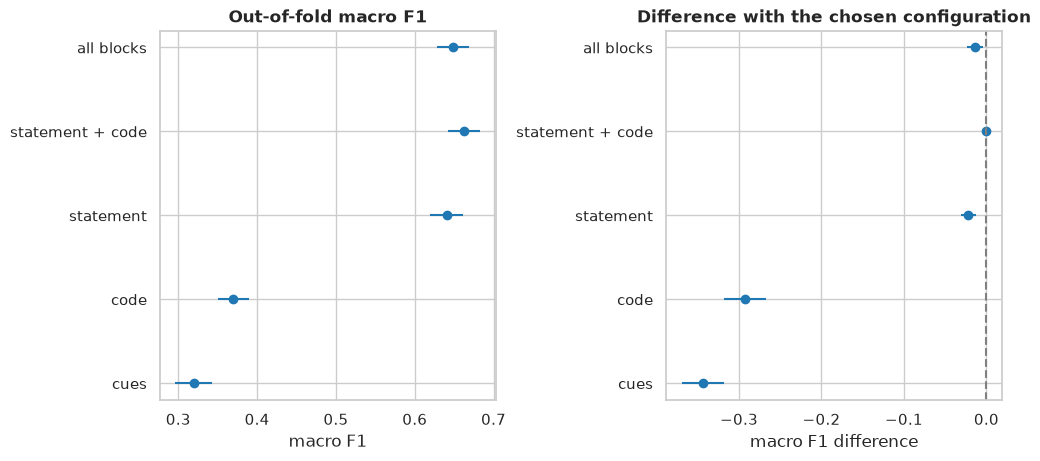

,macro_f1,macro_f1_low,macro_f1_high,delta,delta_low,delta_high
all blocks,0.649,0.628,0.669,-0.014,-0.023,-0.005
statement + code,0.663,0.642,0.683,0.000,0.000,0.000
statement,0.641,0.620,0.661,-0.022,-0.031,-0.013
code,0.370,0.350,0.390,-0.293,-0.319,-0.268
cues,0.320,0.296,0.343,-0.343,-0.370,-0.318


In [19]:
macro_f1 = pd.DataFrame(
    {
        name: scores.summary.loc[ALL_PROBLEMS, ["macro_f1", "macro_f1_low", "macro_f1_high"]]
        for name, scores in ablation_scores.items()
    }
).T
comparisons = {
    name: compare(labels, out_of_fold.predictions, predicted, dev["group"])
    for name, predicted in ablations.items()
}
differences = pd.DataFrame(
    {
        name: comparison.loc["macro_f1", ["delta", "delta_low", "delta_high"]]
        for name, comparison in comparisons.items()
    }
).T
ablation_table = macro_f1.join(differences)
figure, (left, right) = plt.subplots(1, 2, layout="constrained")
plot_intervals(ablation_table, "macro_f1", "macro_f1_low", "macro_f1_high", ax=left)
plot_intervals(ablation_table, "delta", "delta_low", "delta_high", ax=right)
right.axvline(0, color="grey", linestyle="--")
left.set(title="Out-of-fold macro F1", xlabel="macro F1")
right.set(title="Difference with the chosen configuration", xlabel="macro F1 difference")
plt.show()
ablation_table.round(3)

The F1 of each tag in each ablation, then the paired difference of each tag's F1 with the
chosen configuration, with its interval, show which tags a block helps or hurts. The cues
were built for the rare tags (`trees`, `geometry`, `games` and `probabilities`), so those
are the tags where they could pay off. The plot shows the per-tag differences of "all
blocks", the chosen configuration with the cue block added:

F1 per tag:


,all blocks,statement + code,statement,code,cues
tag,,,,,
math,0.572,0.582,0.571,0.506,0.455
graphs,0.599,0.603,0.578,0.528,0.401
strings,0.685,0.690,0.677,0.398,0.256
number theory,0.546,0.541,0.503,0.351,0.147
trees,0.691,0.719,0.697,0.450,0.457
geometry,0.644,0.652,0.607,0.377,0.324
games,0.814,0.835,0.821,0.165,0.288
probabilities,0.641,0.682,0.676,0.183,0.229


Paired difference of each tag's F1 with the chosen configuration:


all blocks                      statement                       \
                   delta delta_low delta_high     delta delta_low delta_high   
label                                                                          
math              -0.010    -0.020      0.001    -0.011    -0.021     -0.002   
graphs            -0.004    -0.021      0.014    -0.025    -0.045     -0.004   
strings           -0.005    -0.020      0.010    -0.013    -0.028      0.001   
number theory      0.005    -0.010      0.018    -0.038    -0.066     -0.011   
trees             -0.028    -0.055     -0.003    -0.022    -0.038     -0.008   
geometry          -0.007    -0.044      0.028    -0.044    -0.082     -0.009   
games             -0.021    -0.056      0.013    -0.015    -0.039      0.000   
probabilities     -0.041    -0.087      0.002    -0.005    -0.043      0.031   

                code                        cues                       
               delta delta_low delta_high  delta delta_low delta_high  
label                                                                  
math          -0.076    -0.097     -0.056 -0.127    -0.145     -0.108  
graphs        -0.075    -0.123     -0.030 -0.202    -0.249     -0.156  
strings       -0.292    -0.340     -0.245 -0.434    -0.493     -0.371  
number theory -0.190    -0.256     -0.125 -0.394    -0.447     -0.342  
trees         -0.268    -0.332     -0.208 -0.261    -0.318     -0.207  
geometry      -0.274    -0.353     -0.197 -0.327    -0.417     -0.246  
games         -0.670    -0.776     -0.560 -0.547    -0.669     -0.427  
probabilities -0.499    -0.599     -0.393 -0.453    -0.554     -0.348

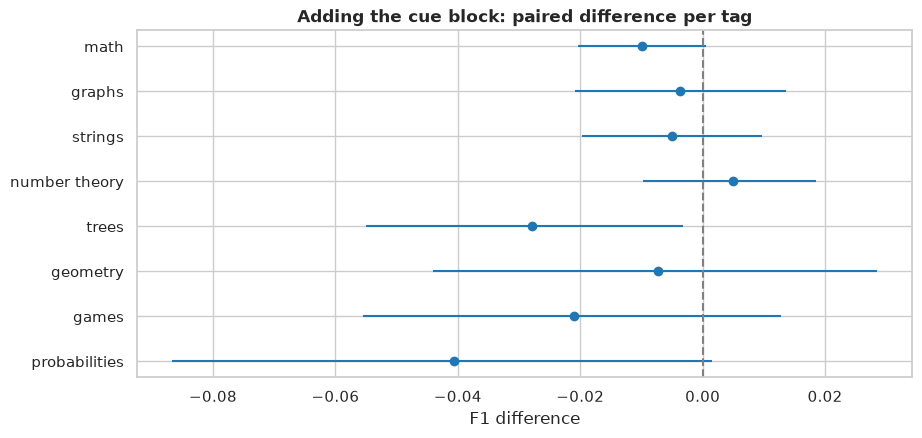

In [20]:
tag_f1 = pd.DataFrame(
    {name: scores.per_tag.loc[ALL_PROBLEMS, "f1"] for name, scores in ablation_scores.items()}
)
print("F1 per tag:")
display(tag_f1.round(3))
tag_differences = pd.concat(
    {
        name: comparison.loc[labels.columns, ["delta", "delta_low", "delta_high"]]
        for name, comparison in comparisons.items()
        if ABLATIONS[name] != results.params.blocks
    },
    axis=1,
)
print("Paired difference of each tag's F1 with the chosen configuration:")
display(tag_differences.round(3))
cue_differences = comparisons["all blocks"].loc[labels.columns]
ax = plot_intervals(cue_differences, "delta", "delta_low", "delta_high")
ax.axvline(0, color="grey", linestyle="--")
ax.set(title="Adding the cue block: paired difference per tag", xlabel="F1 difference")
plt.show()

Adding the cue block lowers the F1 of 7 of the 8 tags, most on `probabilities` (-0.041
[-0.087, 0.002]) and `trees` (-0.028 [-0.055, -0.003]), but only the interval of `trees`
excludes 0: per tag, the cost of the cues is mostly within the noise, and the macro
difference (-0.014 [-0.023, -0.005]) is the finding. Without the code block ("statement"),
every tag's F1 drops, from -0.005 (`probabilities`) to -0.044 (`geometry`).

**A plateau at the top of the study.** The five best trials score between 0.6612 and
0.6629 (section 3), and share the classifier, the class weighting, the blocks and the
notes. The next cell cross-fits the fifth best, which differs from the chosen configuration
only in C and the TF-IDF settings (read from `trials.csv`), fails unless it scores its
frozen value again, and compares it with the chosen configuration, paired:

In [21]:
runner_up = complete.nlargest(5, "value").iloc[-1]
tfidf_settings = [
    "statement_ngram_max",
    "statement_min_df",
    "statement_max_df",
    "statement_sublinear_tf",
    "code_weight",
    "code_ngram_max",
    "code_min_df",
    "code_sublinear_tf",
]
runner_up_params = replace(
    results.params,
    c=runner_up[f"params_c_{results.params.classifier}"],
    **{name: runner_up[f"params_{name}"] for name in tfidf_settings},
)
runner_up_predictions = cross_fit(
    build_pipeline(runner_up_params), dev_raw, labels, dev_raw["fold"]
).predictions
runner_up_f1 = evaluate(labels, runner_up_predictions).macro_f1
assert runner_up_f1 == runner_up["value"], f"{runner_up_f1} != {runner_up['value']} (trials.csv)"
print(
    f"trial {runner_up['number']}, the fifth best: out-of-fold macro F1 {runner_up_f1:.4f}, "
    "as in trials.csv"
)
plateau = compare(labels, out_of_fold.predictions, runner_up_predictions, dev["group"])
plateau.loc[["macro_f1"]].round(4)

trial 193, the fifth best: out-of-fold macro F1 0.6612, as in trials.csv


,baseline,candidate,delta,delta_low,delta_high
metric,,,,,
macro_f1,0.6629,0.6612,-0.0017,-0.0066,0.0033


Trial 193, the fifth best, scores 0.0017 below the chosen configuration: a paired
difference of -0.0017 [-0.0066, 0.0033], an interval about 0.01 wide that includes 0. The
top of the study is a plateau that the dev set cannot rank. The trials near the top differ
by less than the noise of a paired comparison, so choosing the best of them gains little
from luck: the optimism of the selection is of that order, a few thousandths of macro F1
(section 7).

**Where the errors go.** The tag confusion matrix: rows are the true focus tags plus "no
focus tag", columns the predicted tags plus "nothing predicted", and a cell is the share of
the row's problems that got the column's prediction. A problem can have and get several
tags, so a row need not sum to 1. The diagonal is each tag's recall. Off the diagonal: the
tags predicted instead, or as well, and, in the "no focus tag" row, the false positives of
the problems with no focus tag. An off-diagonal cell also counts the problems that have
both tags, rightly predicted: `number theory` problems often have `math` as well, so the
`math` cell of the `number theory` row is high even where those predictions are right. A
cell is a confusion only for the row's problems that lack the column's tag.

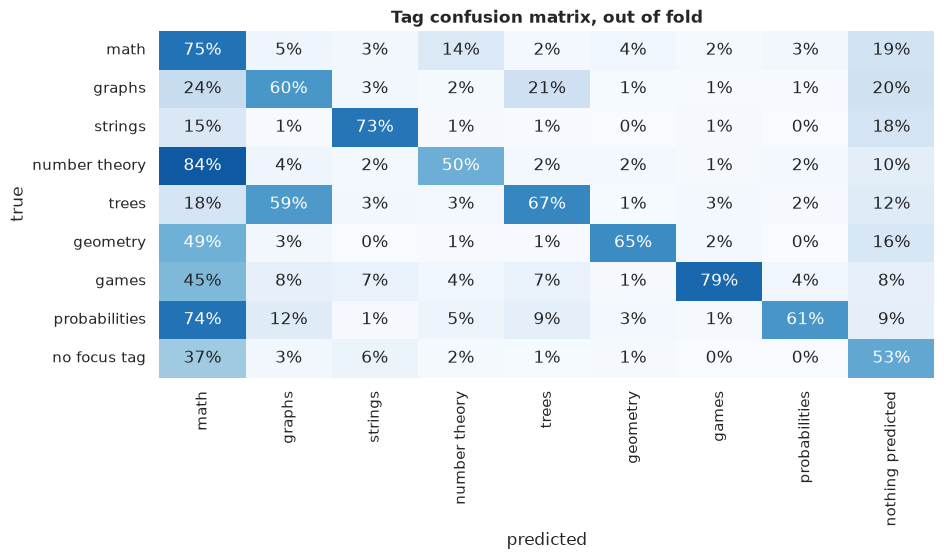

In [22]:
ax = plot_tag_confusion(oof.tag_confusion)
ax.set(title="Tag confusion matrix, out of fold")
plt.show()

The per-tag confusion matrices give the counts behind each F1: TP and FN on the first row
(the problems with the tag), FP and TN on the second. A cell's colour is its share of the
row, so the first row reads as the recall.

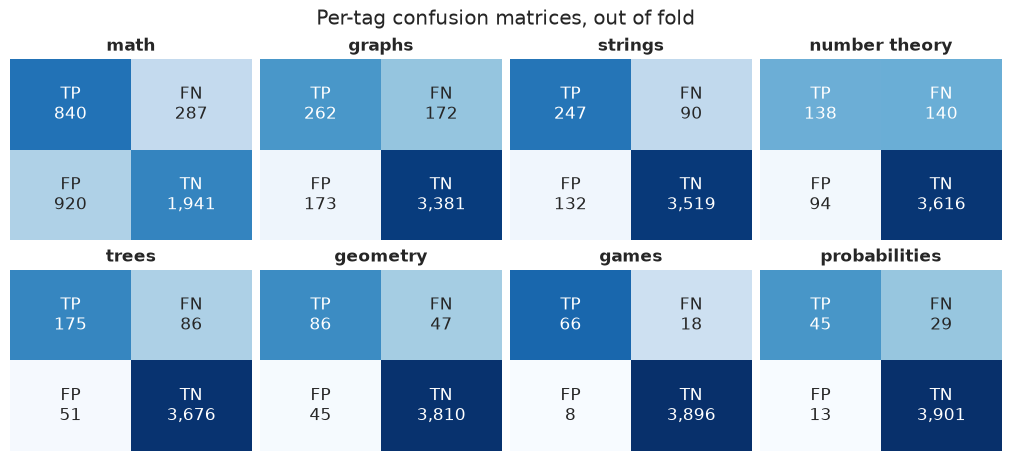

In [23]:
figure = plot_confusion_grid(oof.per_tag.loc[ALL_PROBLEMS])
figure.suptitle("Per-tag confusion matrices, out of fold")
plt.show()

**By slice.** Statements changed format in 2018 (`$$$` LaTeX instead of flattened Unicode),
and the tag mix drifts over time (notebook 01). The F1 of each tag in each slice of the dev
set (the summary above gives the macro and micro F1 of each), and the share of the dev
problems that have each tag in each era:

In [24]:
era = late.map({False: EARLY_ERA, True: LATE_ERA})
pd.concat(
    {
        "F1": oof.per_tag["f1"].unstack("slice").loc[labels.columns, oof.summary.index],
        "share of problems": labels.groupby(era).mean().T[[EARLY_ERA, LATE_ERA]],
    },
    axis=1,
).round(3)

F1                                    \
              all problems focus-tagged up to 2017 from 2018   
label                                                          
math                 0.582        0.764      0.471     0.622   
graphs               0.603        0.650      0.652     0.569   
strings              0.690        0.806      0.667     0.707   
number theory        0.541        0.579      0.497     0.559   
trees                0.719        0.743      0.674     0.745   
geometry             0.652        0.723      0.675     0.618   
games                0.835        0.868      0.833     0.836   
probabilities        0.682        0.703      0.828     0.568   

              share of problems            
                     up to 2017 from 2018  
label                                      
math                      0.191     0.345  
graphs                    0.105     0.111  
strings                   0.086     0.083  
number theory             0.050     0.083  
trees                     0.058     0.071  
geometry                  0.044     0.026  
games                     0.016     0.025  
probabilities             0.017     0.019

`math` scores 0.471 up to 2017 against 0.622 from 2018. Two things change with the era: the
share of `math` problems almost doubles (19.1% against 34.5%), so the same false positives
weigh more against fewer true positives in the older problems; and its top feature, in the
next table, exists only in the LaTeX-era statements. The other tags' gaps between the eras
are smaller, except that of `probabilities` (0.828 against 0.568), a tag of 74 problems in
all, whose F1 in each era rests on a few dozen problems.

**What the model relies on.** The tag model is the method `tfidf`, which
`python -m codeforces_tags.tuning freeze` froze in `assets/methods/tfidf/model/`: the chosen
configuration refit on the whole dev set, with the final thresholds (`fit_tag_model()`),
saved with skops. `load_method(model_dir("tfidf"))` loads it, with no refit: it is the model
whose test predictions section 7 reads. The cell fails unless it was fitted with the chosen
configuration, and checks that it predicts the tags of one problem in under a second,
against the task's budget of 10 seconds (loading the model and the problem not included).
`feature_weights()` gives what each feature adds to each tag's score, its coefficient times
its block's weight. Below, the 10 features (`TERMS_TOP_K`) that raise each tag's score
most, with their block: all of them come from the statement block. Most name the tag's
subject (`tree`, `nodes` and `vertices` for `trees`; `probability` and `expected` for
`probabilities`; `gcd` and `divisors` for `number theory`), and should carry over to new
problems. A few are generic or formatting words (`example one`, `as the` and `cdot cdot`
among the `math` features): they say little about what a problem is about, so they are the
features to distrust. And `math`'s first feature, `le 1e9` (`\le 10^9` after the
normaliser), is a spelling of the LaTeX era: flattened powers stay as they are (section 2),
so an older statement writes `le 109`, and the feature cannot fire on it. The second cell
below counts where it fires; the cells after it trace one problem through the pipeline.

In [25]:
tag_model = load_method(model_dir("tfidf"))
assert tag_model.params == results.params, "the frozen tag model has another configuration"
start = time.perf_counter()
one_problem = tag_model.predicted_tags(dev_raw.iloc[[0]])
assert time.perf_counter() - start < 1, "one prediction should take well under a second"
print(f"problem {one_problem.index[0]}, tags predicted in under 1 s: {one_problem.iloc[0]}")
weights = tag_model.feature_weights()
pd.DataFrame(
    {
        tag: [f"{feature} ({block})" for block, feature in weights[tag].nlargest(TERMS_TOP_K).index]
        for tag in tag_model.tags
    }
)

problem 0, tags predicted in under 1 s: ['math']


,math,graphs,strings,number theory,trees,geometry,games,probabilities
0,le 1e9 (statement),graph (statement),string (statement),prime (statement),tree (statement),coordinates (statement),wins (statement),probability (statement)
1,modulo (statement),connected (statement),strings (statement),divisor (statement),the tree (statement),plane (statement),optimally (statement),the probability (statement)
2,mod (statement),the graph (statement),of lowercase (statement),gcd (statement),nodes (statement),polygon (statement),play optimally (statement),expected (statement)
3,example one (statement),roads (statement),english (statement),common divisor (statement),connected (statement),points (statement),play (statement),the expected (statement)
4,divisors (statement),ne (statement),lowercase (statement),divisor of (statement),path (statement),point (statement),turn (statement),probability that (statement)
5,four (statement),road (statement),the string (statement),common (statement),node (statement),triangle (statement),player (statement),expected value (statement)
6,infinite (statement),cycle (statement),letters (statement),greatest (statement),root (statement),angle (statement),both players (statement),probability of (statement)
7,frac (statement),rightarrow (statement),lowercase english (statement),greatest common (statement),the root (statement),straight (statement),turns (statement),randomly (statement)
8,cdot cdot (statement),edges (statement),word (statement),lcm (statement),vertices (statement),coordinates of (statement),move (statement),frac (statement)
9,as the (statement),connected by (statement),given string (statement),divisors (statement),vertex (statement),lie (statement),make move (statement),random (statement)


In [26]:
statement_block = tag_model.pipeline.named_steps["features"].named_transformers_["statement"]
le_1e9 = statement_block["tfidf"].vocabulary_["le 1e9"]
has_le_1e9 = pd.Series(
    statement_block.transform(dev)[:, le_1e9].toarray().ravel() > 0, index=dev.index
)
pd.DataFrame(
    {
        "problems": era.value_counts(),
        "share with le 1e9": has_le_1e9.groupby(era).mean(),
        "math share": labels["math"].groupby(era).mean(),
        "math share with le 1e9": labels["math"][has_le_1e9].groupby(era[has_le_1e9]).mean(),
        "math share without": labels["math"][~has_le_1e9].groupby(era[~has_le_1e9]).mean(),
    }
).loc[[EARLY_ERA, LATE_ERA]].round(3)

,problems,share with le 1e9,math share,math share with le 1e9,math share without
year,,,,,
up to 2017,1626,0.001,0.191,0.000,0.191
from 2018,2362,0.283,0.345,0.443,0.307


`le 1e9` fires on 28.3% of the dev problems from 2018, and on 0.1% of the older ones. Part
of its weight is real signal: from 2018, 44.3% of the problems where it fires are `math`,
against 30.7% of those where it does not. But on the older problems `math`'s top feature is
almost never there, which is one reason why `math` scores lower on them: the time confound
of notebook 01, carried into the model by the way statements are written.

**One problem through the pipeline.** `trace_problem()` (in
`codeforces_tags.analysis.pipeline_trace`) follows one problem through the loaded tag model,
step by step, by slicing its fitted pipeline: nothing is refitted. The problem is the first
of the dev set (sample id 0), whose tags the tag model predicted above. The model was fitted
on the whole dev set, this problem included, so the trace shows how a score is computed, not
how accurate the model is: the out-of-fold scores above, and the error analysis of section 6,
measure that. First, the problem at each step: the raw fields the model reads,
the text the statement block reads (the statement, then the notes, which this problem lacks)
before and after the normaliser, and the tokens the code block reads in the solution:

In [27]:
trace = trace_problem(tag_model, dev_raw.iloc[[0]])
print("steps:", " -> ".join(trace.steps))
display(trace.steps["raw fields"].to_frame("raw field"))
for step in ["statement", "normalised statement"]:
    print(f"{step}, start:")
    print(textwrap.fill(textwrap.shorten(trace.steps[step], 400, placeholder=" ..."), 100))
print(f"code tokens ({len(trace.steps['code tokens'])}):")
print(textwrap.fill(" ".join(trace.steps["code tokens"]), 100))

steps: raw fields -> statement -> normalised statement -> code tokens


,raw field
prob_desc_description,"Numbers $$$1, 2, 3, \dots n$$$ (each integer from $$$1$$$ to $$$n$$$ once) are written on a board. In one ..."
prob_desc_input_spec,The first line contains one integer $$$t$$$ ($$$1 \le t \le 1000$$$) — the number of test cases. The only ...
prob_desc_output_spec,"For each test case, in the first line, print the minimum possible number left on the board after $$$n - 1$..."
prob_desc_notes,NaN
prob_desc_sample_inputs,"[""1\n4""]"
prob_desc_sample_outputs,"[""2\n2 4\n3 3\n3 1""]"
source_code,"\ndef ii(): return int(input())\ndef mi(): return map(int, input().split())\n\n\nif __name__ == '__main__'..."


statement, start:
Numbers $$$1, 2, 3, \dots n$$$ (each integer from $$$1$$$ to $$$n$$$ once) are written on a board.
In one operation you can erase any two numbers $$$a$$$ and $$$b$$$ from the board and write one
integer $$$\frac{a + b}{2}$$$ rounded up instead. You should perform the given operation $$$n - 1$$$
times and make the resulting number that will be left on the board as small as possible. For ...
normalised statement, start:
numbers 1, 2, 3, dots n (each integer from 1 to n once) are written on a board. in one operation you
can erase any two numbers a and b from the board and write one integer frac {a + b}{2} rounded up
instead. you should perform the given operation n - 1 times and make the resulting number that will
be left on the board as small as possible. for example, if n = 4 , the following course of action
...
code tokens (47):
def ii return int input def mi return map int input split if __name__ __main__ for in range ii ii if
print n3 n2 continue if print n2 continu

Each block turns its text into features: the problem's non-zero values, before the block's
weight, the largest first (`features(block)`). A TF-IDF value grows with the term's count in
the problem (sublinearly for the statement) and with its rarity in the dev set, and the
values of each block have unit length:

In [28]:
for block, values in trace.block_values.items():
    print(f"{block}: {len(values)} non-zero features of {len(trace.weights.loc[block]):,}")
pd.concat(
    {block: trace.features(block).head(TERMS_TOP_K).reset_index() for block in trace.block_values},
    axis=1,
).round(3)

statement: 198 non-zero features of 43,354
code: 23 non-zero features of 2,354


statement             code       
            feature  value   feature  value
0        whiteboard  0.215    answer  0.614
1        new number  0.196        ii  0.406
2             board  0.171        n2  0.374
3         the board  0.166       pop  0.290
4  after operations  0.160        n3  0.222
5        choose and  0.160  continue  0.177
6           left on  0.152        mi  0.149
7           be left  0.147       int  0.129
8            is and  0.122     print  0.127
9           the new  0.115    return  0.117

**From features to tags.** A tag's score is its intercept plus, for each feature, the
feature's value times its weight (`feature_weights()`: the coefficient times the block's
weight), so the score splits into one contribution per feature (`contributions(tag)`); the
cell checks that the contributions and the intercept add up to the score. The tag is
predicted when its score reaches its threshold (`decision`). The 10 features that raise
`math`'s score most, then each tag's decision:

In [29]:
for tag in tag_model.tags:
    total = trace.contributions(tag)["contribution"].sum() + trace.decision.at[tag, "intercept"]
    assert np.isclose(total, trace.decision.at[tag, "score"], rtol=1e-9, atol=0), tag
display(trace.contributions("math").head(TERMS_TOP_K).round(3))
trace.decision.round(3)

value  weight  contribution
block     feature                                 
statement whiteboard   0.215   0.351         0.075
          number is    0.114   0.550         0.063
code      answer       0.614   0.102         0.062
statement numbers and  0.090   0.660         0.059
          new number   0.196   0.270         0.053
          board        0.171   0.280         0.048
          frac         0.053   0.856         0.045
          test         0.063   0.646         0.040
          cdot         0.054   0.733         0.040
          easy to      0.070   0.569         0.040

,score,intercept,threshold,predicted,true
label,,,,,
math,0.494,-0.279,-0.420,1,1
graphs,-0.969,-0.961,-0.455,0,0
strings,-1.240,-0.847,-0.286,0,0
number theory,-1.012,-0.838,-0.447,0,0
trees,-0.937,-0.974,-0.357,0,0
geometry,-1.221,-0.917,-0.390,0,0
games,-1.090,-1.008,-0.319,0,0
probabilities,-1.110,-0.961,-0.618,0,0


Problem 0 asks for the smallest number that can be left on a board by replacing two numbers,
again and again, with their mean rounded up; its tags are `greedy`,
`constructive algorithms`, `math`, `implementation` and `data structures`. Only `math`
reaches its threshold, with a score of 0.494 against -0.420; every other tag's score stays at
least 0.49 below its threshold. The features that lift `math` most are the words of the
problem's own setting (`whiteboard`, `number is`, `numbers and`, `new number`, `board`) and
one code token (`answer`), and none decides alone: the largest adds 0.075 to a score 0.773
above the intercept. Further down come `frac` and `cdot`, LaTeX commands, so spellings of
the statements from 2018 on, and `test`, from the multi-test-case input format, which rose
after 2019 as the share of `math` did (notebook 01): the time confound of `le 1e9`, inside
one problem's score.

## 5. Are its scores probabilities? Calibration, out of fold

The tag model predicts a tag when the tag's score reaches its threshold. Its scores are a
linear SVM's margins: they order the problems, but a margin is not a chance. A probability is
**calibrated** when, among the problems it gives a probability p of a tag, a share p have the
tag. This section asks whether the scores can be read as calibrated probabilities, and
compares four ways to turn out-of-fold scores of the 8 focus tags into probabilities
(`CALIBRATION_METHODS` in `config.py`):

| Id | Name | Probability of a tag |
|---|---|---|
| `logistic_regression` | logistic regression | the logistic function of the out-of-fold logit of section 1's logistic regression |
| `svm_minmax` | SVM, min-max | the tag model's out-of-fold margin, min-max scaled with the lowest and highest margins of the other folds, and clipped to [0, 1]: the naive reading of a margin |
| `svm_platt` | SVM + Platt | the same margin through a Platt scaling: a logistic regression on that one score, without a penalty |
| `svm_isotonic` | SVM + isotonic | the same margin through an isotonic regression: a non-decreasing step function of that score |

Everything is read on the dev set, out of fold, and the test set is not used
([ADR 0001](../docs/adr/0001-model-selection-protocol.md)). Nothing is refitted: the margins
are the frozen tag model's out-of-fold scores (`out_of_fold_scores()`), which the next cell
checks are those of section 4, and the logits are section 1's, for the focus tags. The
min-max scaling, Platt scaling and isotonic regression of fold k are fitted on the other four
folds, as fold k's thresholds were chosen (`probabilities_by_method()`, in
`codeforces_tags.evaluation.calibration`): no problem's probability comes from a map fitted on
it.

In [30]:
svm_scores = tag_model.out_of_fold_scores()
assert svm_scores.index.equals(dev_raw.index), "the out-of-fold scores are not the dev problems'"
pd.testing.assert_frame_equal(svm_scores, out_of_fold.scores, check_exact=True)
probabilities = probabilities_by_method(
    svm_scores, first_look.scores[labels.columns], labels, dev_raw["fold"]
)
print(
    f"{svm_scores.size:,} problem-tag pairs, {labels.to_numpy().mean():.1%} of them positive; "
    f"SVM margins from {svm_scores.min().min():.2f} to {svm_scores.max().max():.2f}"
)

31,904 problem-tag pairs, 8.6% of them positive; SVM margins from -1.65 to 1.63


**All problem-tag pairs.** A reliability diagram sorts the pairs by predicted probability
into 10 bins of equal counts (`CALIBRATION_BINS`; `CALIBRATION_STRATEGY` is `"quantile"`,
since equal-width bins would leave the high end nearly empty), and draws each bin at its mean
predicted probability against its share of positives (`plot_reliability()`, over
scikit-learn's `CalibrationDisplay`). A calibrated method's points lie on the dotted
diagonal; below it, a method's probabilities are too high (it over-predicts the tag), above
it too low. Under the diagram, how each method spreads its probabilities: the pairs in each
tenth of [0, 1], on a log scale.

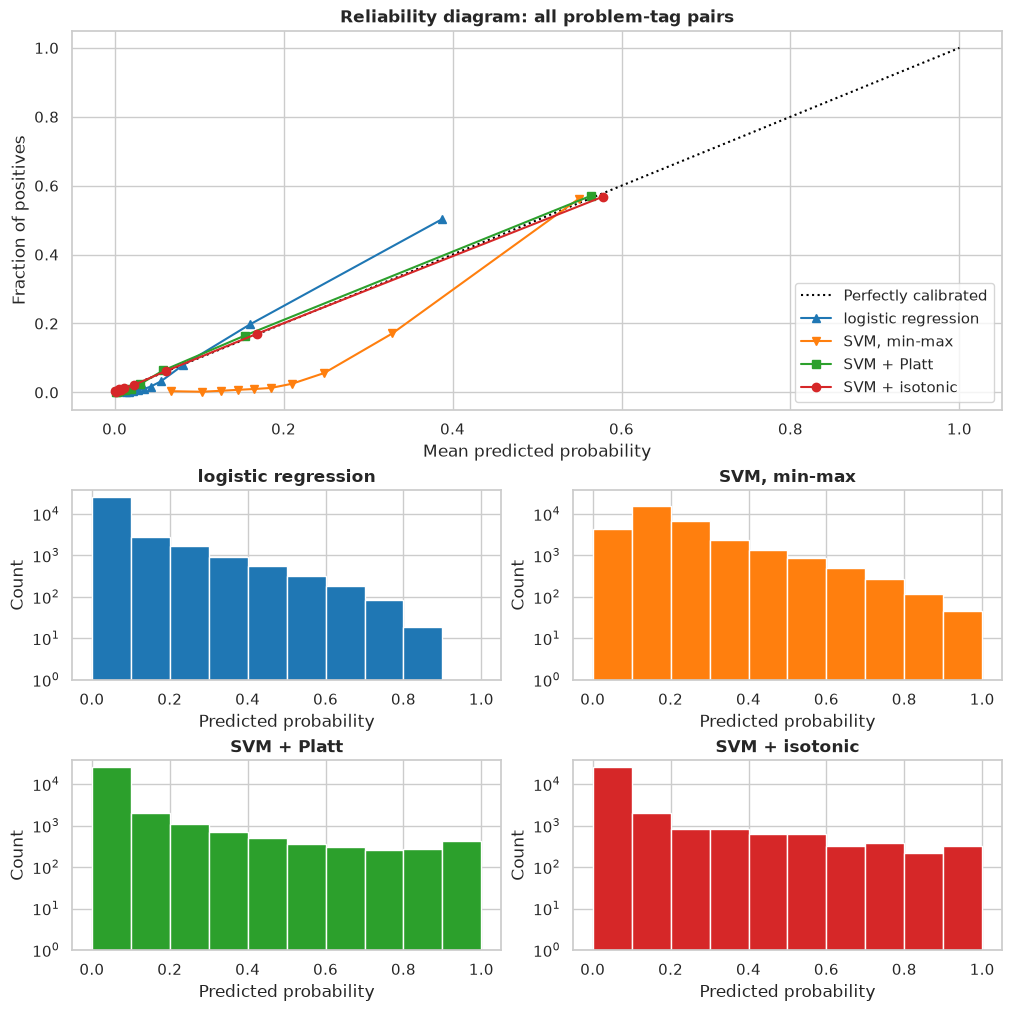

In [31]:
reliability = plot_reliability(probabilities, labels)
plt.show()

Platt scaling and isotonic regression follow the diagonal. The logistic regression's sigmoid
lies above it at the top: its last bin predicts about 0.39 where about half of the pairs are
positive, and its histogram has no pair at 0.9 or more. Its probabilities are squeezed toward
the share of positives, underconfident at the top. Min-max scaling lies far below the
diagonal: it gives most pairs between 0.1 and 0.3, where almost none is positive, so its
probabilities are too high.

**Per tag.** The same diagram for each tag alone (`plot_reliability_grid()`). Quantile bins
merge where a method gives many problems the same probability: the isotonic curve has 8
points for `geometry` and 9 for `games`, the others 10. A rare tag gives few problems a high
probability, so the curves of `geometry`, `games` and `probabilities` stop at mean
predictions between 0.03 and 0.39, in the lower left of their diagrams.

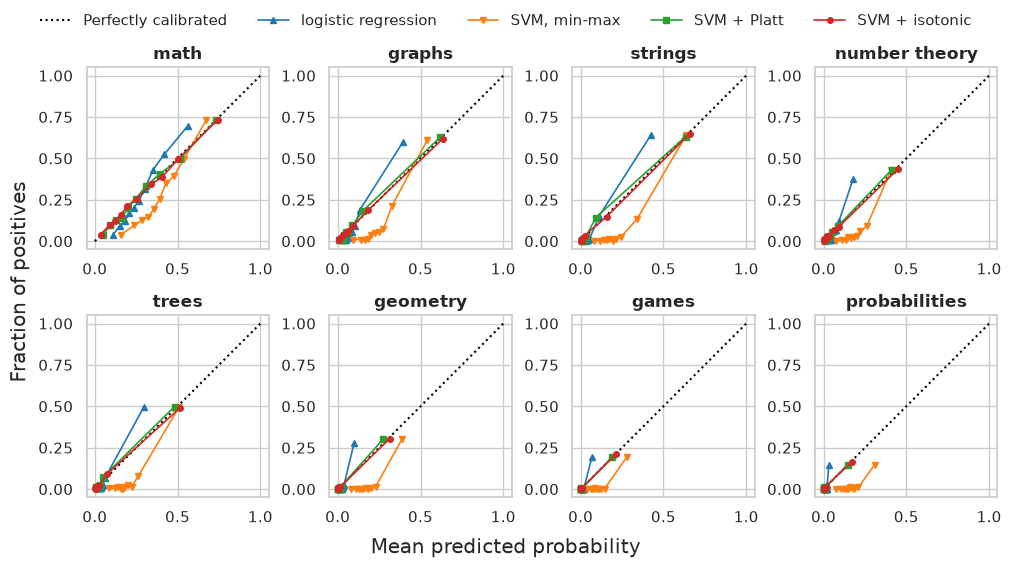

In [32]:
reliability_by_tag = plot_reliability_grid(probabilities, labels)
plt.show()

Tag by tag, the picture is the same: Platt scaling and isotonic regression near the
diagonal, the sigmoid above it at the top, min-max scaling below it.

**Scores.** `calibration_table()` scores each method's probabilities per tag, and over all
problem-tag pairs (`all`), by three measures:
- the **Brier score**, the mean squared difference between the probability and the label (1
  or 0): lower is better;
- the **log loss**, the mean of -log of the probability given to the true label, which
  punishes a confident mistake most. A probability is clipped to [ε, 1 - ε] first, as
  scikit-learn's `log_loss` clips it, so a probability of exactly 0 for a positive costs
  -log ε = 36.04 rather than infinity: lower is better;
- the **Brier skill**, 1 - Brier score / (p (1 - p)), with p the tag's share of positives:
  the share of the Brier score of the constant forecast p that the method saves. 0 is no
  better than that constant, below 0 worse; over all pairs, the ratio is that of the sums
  over the tags.

Each has a 95% group bootstrap interval, from the 2,000 resamples of near-duplicate groups
that `evaluate()` draws, the same for every method, with p recomputed in each. The first line
counts the pairs given a wrong certainty: a probability of exactly 0 for a positive, or of
exactly 1 for a negative. `python -m codeforces_tags.tracking calibrate` logs this table and
both figures to the MLflow run of `tfidf`.

In [33]:
calibration = calibration_table(probabilities, labels, dev_raw["group"])
print(
    "pairs given a wrong certainty: "
    + ", ".join(
        f"{method} {(frame.to_numpy() == 1 - labels.to_numpy()).sum()}"
        for method, frame in probabilities.items()
    )
)
print("Over all problem-tag pairs:")
display(calibration.xs(POOLED, level="tag").round(3))
print("Brier skill per tag:")
calibration["brier_skill"].unstack("method")[list(probabilities)].round(3)

pairs given a wrong certainty: logistic_regression 0, svm_minmax 1, svm_platt 0, svm_isotonic 19
Over all problem-tag pairs:


,brier,brier_low,brier_high,log_loss,log_loss_low,log_loss_high,brier_skill,brier_skill_low,brier_skill_high
method,,,,,,,,,
logistic_regression,0.054,0.053,0.056,0.189,0.184,0.194,0.244,0.232,0.255
svm_minmax,0.067,0.066,0.068,0.269,0.266,0.273,0.062,0.039,0.083
svm_platt,0.047,0.045,0.048,0.161,0.156,0.167,0.351,0.332,0.370
svm_isotonic,0.046,0.045,0.048,0.178,0.167,0.190,0.355,0.336,0.373


Brier skill per tag:


method,logistic_regression,svm_minmax,svm_platt,svm_isotonic
tag,,,,
math,0.173,0.129,0.207,0.202
graphs,0.279,0.128,0.359,0.368
strings,0.421,0.165,0.478,0.489
number theory,0.154,0.017,0.314,0.321
trees,0.372,0.105,0.505,0.519
geometry,0.180,-0.308,0.427,0.434
games,0.275,0.090,0.680,0.687
probabilities,0.058,-0.837,0.485,0.475
all,0.244,0.062,0.351,0.355


Platt scaling and isotonic regression score the best Brier skill over all pairs, 0.351
[0.332, 0.370] and 0.355 [0.336, 0.373], with intervals that overlap almost entirely. The
sigmoid follows at 0.244 [0.232, 0.255]. Min-max scaling, at 0.062 [0.039, 0.083], is barely
better than the constant forecast, and worse than it on `geometry` (-0.308) and
`probabilities` (-0.837). Both calibrated SVMs beat the sigmoid on every tag, most on `games`
and `probabilities` (0.680 and 0.485 for Platt scaling, against 0.275 and 0.058). By log
loss, Platt scaling comes first (0.161 against 0.178): isotonic regression gives 19 pairs a
wrong certainty, which at 36.04 each add 19 × 36.04 / 31,904 = 0.021 to its mean, more than
its gap to Platt scaling.

**F1 does not move.** Calibration need not change a prediction. One Platt map per tag, fitted
on all its out-of-fold scores (`platt_maps()`), increases: the cell fails unless each slope is
above 0. Mapping the scores, and each fold's cross-fitted thresholds, through these maps
(`mapped_predictions()`) should then give the predictions of section 4. In floating point, a
map that increases can still round a score just below its threshold up to the threshold's
probability, so the cell counts the cells that differ rather than assume that none does, and
fails unless none does and the macro F1 is section 4's exactly. The slope and intercept of
each map:

In [34]:
maps = platt_maps(svm_scores, labels)
mapped = mapped_predictions(svm_scores, out_of_fold.fold_thresholds, dev_raw["fold"], maps)
assert mapped.shape == tag_model.estimator.oof_predictions_.shape, mapped.shape
differing = int((mapped.to_numpy() != tag_model.estimator.oof_predictions_).sum())
assert differing == 0, f"{differing} out-of-fold predictions change"
pd.testing.assert_frame_equal(mapped, out_of_fold.predictions, check_exact=True)
mapped_f1 = evaluate(labels, mapped).macro_f1
assert mapped_f1 == oof.macro_f1, f"{mapped_f1!r} != {oof.macro_f1!r}"
print(f"{differing} of {mapped.size:,} cells differ; macro F1 {mapped_f1!r}, section 4's exactly")
pd.DataFrame(
    {
        "slope": [fitted.coef_[0, 0] for fitted in maps.values()],
        "intercept": [fitted.intercept_[0] for fitted in maps.values()],
    },
    index=labels.columns,
).round(3)

0 of 31,904 cells differ; macro F1 0.6629367124205685, section 4's exactly


,slope,intercept
label,,
math,2.570,0.002
graphs,3.914,0.419
strings,4.132,0.140
number theory,5.050,1.207
trees,4.658,0.599
geometry,6.652,1.837
games,7.412,1.837
probabilities,9.487,4.324


None of the 31,904 cells differs, and the macro F1 is section 4's to the last digit. The
slopes run from 2.57 for `math`, the most frequent tag, to 9.49 for `probabilities`, the
rarest.

**Where the thresholds fall.** For calibrated probabilities, the threshold that maximises F1
is half the F1 it reaches (Lipton, Elkan and Narayanaswamy, 2014). `lipton_table()` maps each
tag's final threshold (chosen on all its out-of-fold scores, as in `thresholds.json`) through
the tag's Platt map, and sets it beside half the F1 that those thresholds reach on the scores
they were chosen on, the pooled F1 of section 4 (`pooled_gap`), with their ratio:

In [35]:
lipton = lipton_table(
    out_of_fold.thresholds, maps, pooled_gap.loc[list(labels.columns), "candidate"]
)
lipton.assign(ratio=lipton["probability_threshold"] / lipton["half_f1"]).round(3)

,threshold,probability_threshold,f1,half_f1,ratio
tag,,,,,
math,-0.420,0.254,0.583,0.292,0.870
graphs,-0.455,0.204,0.611,0.305,0.668
strings,-0.286,0.261,0.698,0.349,0.748
number theory,-0.447,0.259,0.547,0.274,0.948
trees,-0.357,0.256,0.723,0.361,0.710
geometry,-0.390,0.319,0.659,0.330,0.968
games,-0.319,0.371,0.835,0.418,0.889
probabilities,-0.618,0.177,0.696,0.348,0.508


Every mapped threshold lies below half its tag's F1, at 0.51 (`probabilities`) to 0.97
(`geometry`) of it: the rule holds only roughly here. It assumes probabilities calibrated at
the threshold itself, and a Platt map, two numbers fitted over all of a tag's scores, only
comes close to that. But every threshold, mapped, lies far below 0.5, from 0.177
(`probabilities`) to 0.371 (`games`), as the rule has it for any F1 below 1. That is why
scikit-learn's default of 0.5 failed in section 1: a probability of 0.5 is far above the
threshold that maximises F1, even for calibrated probabilities, and the first look's
probabilities, squeezed toward the share of positives, seldom reach it.

**What calibration changes.** Here, no prediction: each tag has its own threshold, chosen on
its own scores, and a map that increases keeps the order of the scores, so the predictions and
the F1 are those of section 4. Calibration matters when a score is used for more than its
order: to read it as the chance that a problem has the tag, to share one threshold between the
tags, or to combine the scores of several methods, which adds up only on a common scale. A
calibrated `predict_proba` on the tag model, a Platt map per tag fitted on its out-of-fold
scores, is a later option (section 8).

## 6. What it gets wrong, out of fold

The errors are read on the out-of-fold predictions of section 4, never on the test set:
reading the test set's errors would turn it into a second dev set. Per tag, the false
positives on no-focus problems, among them the untagged ones, whose labels may be
incomplete (notebook 01); the others fall on problems with another focus tag:

In [36]:
predicted = out_of_fold.predictions
false_positive = (predicted == 1) & (labels == 0)
no_focus = ~labels.any(axis=1)
untagged = dev["tags"].str.len() == 0
pd.DataFrame(
    {
        "false positives": false_positive.sum(),
        "on no-focus problems": false_positive[no_focus].sum(),
        "on untagged problems": false_positive[untagged].sum(),
        "false negatives": ((predicted == 0) & (labels == 1)).sum(),
    }
)

,false positives,on no-focus problems,on untagged problems,false negatives
label,,,,
math,920,688,8,287
graphs,173,63,4,172
strings,132,103,0,90
number theory,94,33,1,140
trees,51,16,4,86
geometry,45,26,3,47
games,8,6,0,18
probabilities,13,4,0,29


**The weakest tag.** The tag with the lowest out-of-fold F1, and its first false positives
and false negatives by sample id, with all their tags and the start of their statement:

In [37]:
weakest = per_tag["f1"].idxmin()
print(f"weakest tag out of fold: {weakest}, F1 {per_tag.at[weakest, 'f1']:.3f}")
for kind in ("false positive", "false negative"):
    print(f"{kind}s:")
    display(misclassified(dev, labels, predicted, weakest, kind))

weakest tag out of fold: number theory, F1 0.541
false positives:


,tags,statement
sample_id,,
57,"[constructive algorithms, greedy]",An integer sequence is called beautiful if the difference between any two consecutive numbers is equal to ...
98,"[binary search, math]",You are given two positive integers $$$n$$$ and $$$k$$$. Print the $$$k$$$-th positive integer that is not...
130,"[binary search, meet-in-the-middle, greedy, math]",The only difference between easy and hard versions is the maximum value of $$$n$$$. You are given a positi...
144,"[constructive algorithms, math]",Today the kindergarten has a new group of $$$n$$$ kids who need to be seated at the dinner table. The chai...
186,"[brute force, math]",Let's call a positive integer composite if it has at least one divisor other than $$$1$$$ and itself. For ...


false negatives:


,tags,statement
sample_id,,
1,"[number theory, greedy]","There are $$$n$$$ positive integers $$$a_1, a_2, \dots, a_n$$$. For the one move you can choose any even v..."
9,"[number theory, math, matrices]","You are given two integers $$$a$$$ and $$$b$$$. Moreover, you are given a sequence $$$s_0, s_1, \dots, s_{..."
23,"[greedy, number theory, bitmasks, math, implementation, ternary search]","Suppose you are performing the following algorithm. There is an array $$$v_1, v_2, \dots, v_n$$$ filled wi..."
24,"[number theory, math]",Polycarp wants to buy exactly $$$n$$$ shovels. The shop sells packages with shovels. The store has $$$k$$$...
30,"[number theory, math]",Katya studies in a fifth grade. Recently her class studied right triangles and the Pythagorean theorem. It...


**The untagged problems that get a focus tag.** Notebook 01 found that a few of the
untagged problems look like tree, graph or game problems, so some of these false positives
may be right, and worth a manual check:

In [38]:
flagged = predicted[untagged & predicted.any(axis=1)]
flagged.loc[:, flagged.any()].join(dev["statement"].str[:ERROR_EXCERPT_CHARS])

,math,graphs,number theory,trees,geometry,statement
sample_id,,,,,,
43,1,0,0,0,0,Let's call an array good if there is an element in the array that equals to the sum of all other elements....
568,1,0,0,0,0,"Vlad likes to eat in cafes very much. During his life, he has visited cafes n times. Unfortunately, Vlad s..."
599,0,0,0,0,1,The zombies are gathering in their secret lair! Heidi will strike hard to destroy them once and for all. B...
1080,0,1,0,1,0,Heidi has finally found the mythical Tree of Life – a legendary combinatorial structure which is said to c...
1175,1,0,0,0,1,"There are n points on a straight line, and the i-th point among them is located at xi. All these coordinat..."
1599,1,0,0,0,0,Codeforces is a wonderful platform and one its feature shows how much someone contributes to the community...
2035,1,0,0,0,0,Chubby Yang is studying linear equations right now. He came up with a nice problem. In the problem you are...
2226,1,0,0,0,0,"Sereja has an n × m rectangular table a, each cell of the table contains a zero or a number one. Sereja wa..."
2630,0,1,0,1,0,A tree of size n is an undirected connected graph consisting of n vertices without cycles. Consider some t...


## 7. The test set, scored once

Two models score the test set, each once, and nothing is chosen or changed because of their
scores: that would make the test set a second dev set. First, for reference only, the
logistic regression of section 1, scored here. Then the tag model of section 4, whose test
set `python -m codeforces_tags.tuning freeze` scored once, when it froze the model: this
section reads its frozen test predictions (`assets/methods/tfidf/predictions.csv`), and
checks that the loaded tag model predicts every test problem as they say.

**Reference: the logistic regression of section 1.**
`CrossFittedTagThresholds(first_look_pipeline(), refit=True)` cross-fits it again on the dev
folds, chooses each tag's threshold on all of that tag's out-of-fold scores (as for the
tuned model's final thresholds), then refits it on all 3,988 dev problems and every tag. The
cell fails unless those thresholds are the ones chosen on section 1's out-of-fold scores
(`per_tag_thresholds()`), and unless the focus tags' test macro F1 is exactly
0.6472796222382897, as when the test set was first scored. Its test macro F1 next to its
out-of-fold one:

In [39]:
test_raw = select_part(raw, split, "test")
test = select_part(df, split, "test")
test_tags = multi_hot(test_raw["tags"], vocabulary=all_tags.columns)
first_look_final = CrossFittedTagThresholds(first_look_pipeline(), refit=True)
first_look_final.fit(dev_raw, all_tags, groups=dev_raw["fold"])
assert np.array_equal(
    first_look_final.thresholds_, per_tag_thresholds(first_look.scores, all_tags).to_numpy()
), "the refit's thresholds are not those of section 1's out-of-fold scores"
first_look_test = pd.DataFrame(
    first_look_final.predict(test_raw), index=test_raw.index, columns=all_tags.columns
)
first_look_reference = pd.DataFrame(
    {
        "out of fold (dev)": first_look_macro_f1["cross-fitted thresholds"],
        "test": {
            f"focus tags ({is_focus.sum()})": f1_score(
                test_tags.loc[:, is_focus],
                first_look_test.loc[:, is_focus],
                average="macro",
                zero_division=0,
            ),
            f"other tags ({(~is_focus).sum()})": f1_score(
                test_tags.loc[:, ~is_focus],
                first_look_test.loc[:, ~is_focus],
                average="macro",
                zero_division=0,
            ),
            f"all tags ({all_tags.shape[1]})": f1_score(
                test_tags, first_look_test, average="macro", zero_division=0
            ),
        },
    }
)
first_look_test_f1 = first_look_reference.at[focus_row, "test"]
assert first_look_test_f1 == 0.6472796222382897, f"{first_look_test_f1!r} != 0.6472796222382897"
absent = test_tags.columns[test_tags.sum().eq(0)]
print(f"test set: {len(test):,} problems; tags with no test problem: {list(absent) or 'none'}")
first_look_reference.round(3)

test set: 994 problems; tags with no test problem: ['schedules']


,out of fold (dev),test
focus tags (8),0.612,0.647
other tags (29),0.260,0.288
all tags (37),0.336,0.365


The logistic regression keeps its picture on the test set: a macro F1 of 0.647 on the
focus tags against 0.288 on the other tags and 0.365 over all 37, close to its out-of-fold
0.612, 0.260 and 0.336.
`schedules` has no test problem, so its F1 counts as 0 among the other tags. The tuned
model, next, scores 0.689 on the focus tags.

**The tag model of section 4**, scored once by `tuning freeze`. Its frozen test
predictions; the cell fails unless the loaded tag model predicts exactly these tags for
every test problem, and unless their macro F1 is `TFIDF_TEST_MACRO_F1`, the score recorded
when the test set was scored. The summary per slice, as in section 4:

In [40]:
test_predictions = load_predictions(method_dir("tfidf")).loc["test"]
assert tag_model.predict(test_raw).equals(test_predictions), "not the frozen test predictions"
test_labels = focus_labels(test)
test_scores = evaluate(
    test_labels,
    test_predictions,
    release_years=release_years(test),
    groups=test["group"],
)
assert test_scores.macro_f1 == TFIDF_TEST_MACRO_F1, f"{test_scores.macro_f1!r} (test)"
print(f"test set: {len(test):,} problems, {test['group'].nunique():,} near-duplicate groups")
test_scores.summary[summary_columns].round(3)

test set: 994 problems, 981 near-duplicate groups


,problems,macro_f1,macro_f1_low,macro_f1_high,micro_f1,micro_f1_low,micro_f1_high,no_focus_nothing_predicted
slice,,,,,,,,
all problems,994,0.689,0.649,0.721,0.633,0.604,0.661,0.545
focus-tagged,535,0.752,0.716,0.784,0.742,0.716,0.769,NaN
up to 2017,407,0.639,0.565,0.693,0.580,0.530,0.631,0.636
from 2018,587,0.705,0.648,0.748,0.661,0.626,0.694,0.460


**Per tag**, over all test problems: the per-tag confusion matrix, precision, recall and F1,
and the interval of F1:

In [41]:
test_per_tag = test_scores.per_tag.loc[ALL_PROBLEMS]
counts = ["support", "tp", "fp", "fn"]
test_per_tag[[*counts, "precision", "recall", "f1", "f1_low", "f1_high"]].round(3)

,support,tp,fp,fn,precision,recall,f1,f1_low,f1_high
tag,,,,,,,,,
math,281,218,205,63,0.515,0.776,0.619,0.574,0.662
graphs,108,61,50,47,0.550,0.565,0.557,0.474,0.634
strings,85,64,45,21,0.587,0.753,0.660,0.574,0.736
number theory,72,36,31,36,0.537,0.500,0.518,0.406,0.622
trees,63,44,7,19,0.863,0.698,0.772,0.674,0.850
geometry,33,24,11,9,0.686,0.727,0.706,0.576,0.817
games,21,18,2,3,0.900,0.857,0.878,0.755,0.973
probabilities,18,16,6,2,0.727,0.889,0.800,0.628,0.917


Both confusion matrices, read as in section 4:

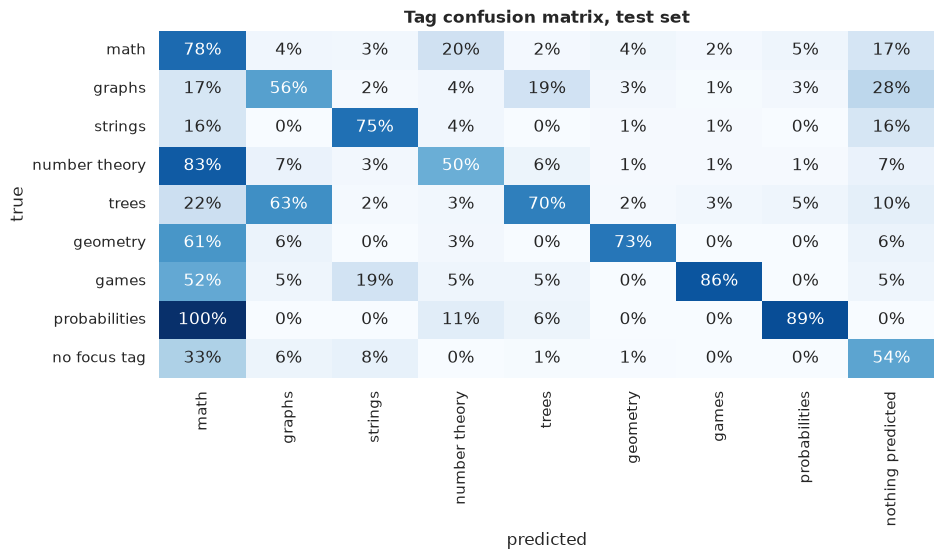

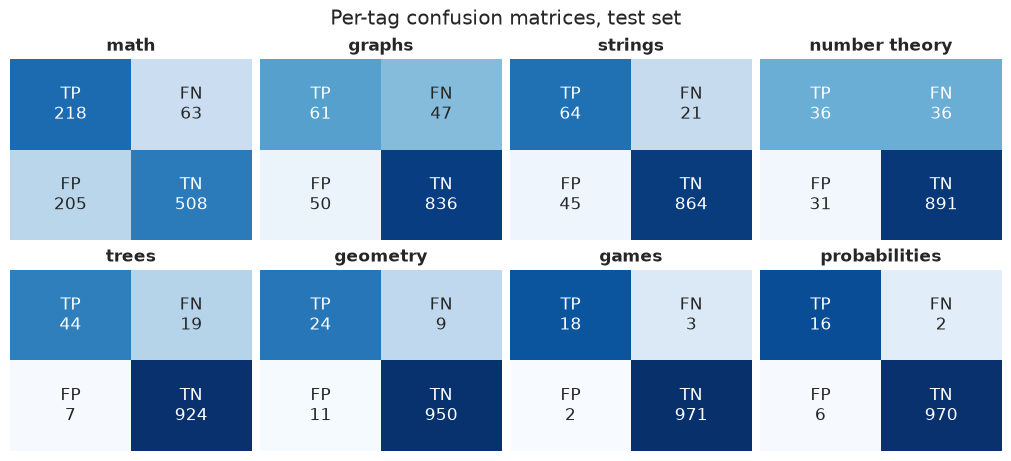

In [42]:
ax = plot_tag_confusion(test_scores.tag_confusion)
ax.set(title="Tag confusion matrix, test set")
plt.show()
figure = plot_confusion_grid(test_per_tag)
figure.suptitle("Per-tag confusion matrices, test set")
plt.show()

The F1 of each tag in each slice of the test set: all problems against the focus-tagged
ones, and the two release eras.

In [43]:
test_f1 = test_scores.per_tag["f1"].unstack("slice")
test_f1.loc[test_labels.columns, test_scores.summary.index].round(3)

slice,all problems,focus-tagged,up to 2017,from 2018
label,,,,
math,0.619,0.787,0.530,0.655
graphs,0.557,0.632,0.529,0.576
strings,0.660,0.815,0.629,0.686
number theory,0.518,0.522,0.476,0.536
trees,0.772,0.800,0.621,0.824
geometry,0.706,0.738,0.727,0.686
games,0.878,0.900,0.769,0.929
probabilities,0.800,0.821,0.833,0.750


**Out of fold against test.** Both score the chosen configuration on problems it was not
fitted on, from two disjoint sets of problems, but three things pull them apart:
- **Selection.** The out-of-fold macro F1 is the best of 203 trials, and the best of many
  noisy scores tends to sit above its own true value: that makes it optimistic. The
  plateau of section 4 suggests that it does so by little: the fifth-best trial is within
  a paired -0.0017 [-0.0066, 0.0033] of the chosen one.
- **More training data.** The test model is refit on all 3,988 dev problems, about a
  quarter more than the four folds of five that each out-of-fold pipeline is fitted on,
  which helps on test.
- **Threshold transfer.** The test model's thresholds were chosen on the scores of
  pipelines fitted on four folds. With C fixed, a fit on more problems can shift the scale
  of the scores, so the thresholds transfer to it only approximately.

The test intervals are wider, since the test set is a quarter of the dev set's size. The
table below puts the out-of-fold macro F1 (0.663) inside the test interval ([0.649, 0.721],
around a test macro F1 of 0.689): the two agree within resampling noise. So the test score
shows no optimism large enough for its interval, of half-width about 0.036, to detect; the
plateau is the stronger sign that the selection flattered the chosen configuration by
little.

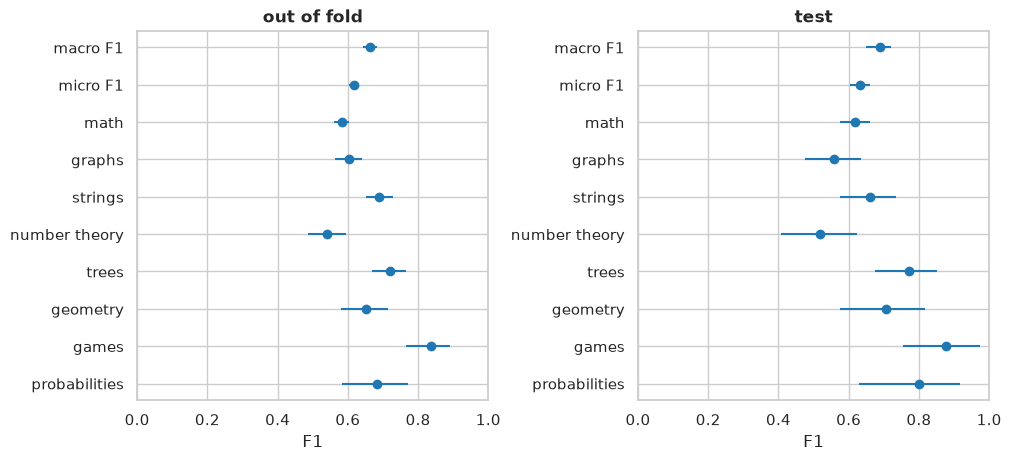

out of fold                 test              
                       f1    low   high     f1    low   high
macro F1            0.663  0.642  0.683  0.689  0.649  0.721
micro F1            0.617  0.604  0.632  0.633  0.604  0.661
math                0.582  0.560  0.604  0.619  0.574  0.662
graphs              0.603  0.563  0.639  0.557  0.474  0.634
strings             0.690  0.652  0.730  0.660  0.574  0.736
number theory       0.541  0.487  0.595  0.518  0.406  0.622
trees               0.719  0.668  0.766  0.772  0.674  0.850
geometry            0.652  0.581  0.715  0.706  0.576  0.817
games               0.835  0.765  0.891  0.878  0.755  0.973
probabilities       0.682  0.582  0.772  0.800  0.628  0.917

In [44]:
side_by_side = {}
for name, scores in {"out of fold": oof, "test": test_scores}.items():
    overall = scores.summary.loc[ALL_PROBLEMS]
    tag_rows = scores.per_tag.loc[ALL_PROBLEMS]
    side_by_side[name] = pd.DataFrame(
        {
            "f1": [overall["macro_f1"], overall["micro_f1"], *tag_rows["f1"]],
            "low": [overall["macro_f1_low"], overall["micro_f1_low"], *tag_rows["f1_low"]],
            "high": [overall["macro_f1_high"], overall["micro_f1_high"], *tag_rows["f1_high"]],
        },
        index=["macro F1", "micro F1", *tag_rows.index],
    )
figure, axes = plt.subplots(1, 2, layout="constrained")
for ax, (name, table) in zip(axes, side_by_side.items(), strict=True):
    plot_intervals(table, "f1", "low", "high", ax=ax)
    ax.set(title=name, xlabel="F1", xlim=(0, 1))
plt.show()
pd.concat(side_by_side, axis=1).round(3)

## 8. Takeaways and next steps

**Results**
- **A first look** (section 1). One untuned logistic regression on the statement scores a
  macro F1 of 0.612 out of fold on the 8 focus tags against 0.260 on the 29 other tags (0.336
  over all 37), and 0.647 against 0.288 (0.365) on the test set, scored once for reference: the focus tags are the
  easier ones. The tuned model lifts the focus tags to 0.663 out of fold and 0.689 on test.
- **Against the paper.** The xCodeEval paper's Python baseline, `gpt-3.5-turbo` asked
  zero-shot, scores a macro F1 of 0.337 from the description and the solution over about 31
  tags, on its validation split (p.6). The untuned logistic regression of section 1 is on
  par over all 37 tags (0.336 out of fold, 0.365 on test). Different tag sets, splits and
  solutions per problem make this context, not a leaderboard
  ([paper notes](../docs/xcodeeval-paper-notes.md), section 5).
- **The chosen configuration** is a linear SVM on the statement and code blocks, with no
  cues (section 3). Its out-of-fold macro F1 is 0.663 [0.642, 0.683], and its test macro
  F1, scored once, 0.689 [0.649, 0.721].
- **Out of fold and test agree.** The out-of-fold macro F1 lies inside the test interval,
  so the two agree within resampling noise. The test score shows no optimism large enough
  for its interval (half-width about 0.036) to detect; the plateau below is the stronger
  sign that choosing among 203 trials flattered the chosen configuration by little.
- **The cues did not help.** Adding the cue block to the chosen configuration, at the cue
  weight of 0.521 of the best trial that kept them, lowers the out-of-fold macro F1: the
  paired difference is -0.014 [-0.023, -0.005], an interval that excludes 0 (section 4).
  The study agrees in direction: its best trial with cues, among only 26 (22 of them
  random), scores 0.6479 against 0.6629 (section 3). Per tag, the difference is negative
  on 7 of 8 tags and largest on `probabilities` (-0.041 [-0.087, 0.002]) and `trees`
  (-0.028 [-0.055, -0.003]), but only the interval of `trees` excludes 0: per tag, the cost
  of the cues is mostly within the noise. The ablation favours the chosen blocks, since the
  other settings were tuned for them.
- **The code block helps.** The statement alone scores 0.641 out of fold, a paired
  difference of -0.022 [-0.031, -0.013] with the chosen configuration (section 4). The
  study never tried a model without the code block (`code_weight` is at least 0.1), so this
  ablation has no re-tuned counterpart.
- **Per tag.** `number theory` is the weakest tag out of fold (F1 0.541 [0.487, 0.595]) and
  `games` the best (0.835 [0.765, 0.891]). `probabilities` has the widest interval, then
  `geometry` and `games`, so a few points of F1 between the rare tags is noise.
- **A plateau.** The five best trials score between 0.6612 and 0.6629 (section 3), and all
  are linear SVMs without cues and without class weights, with the notes read. The chosen
  configuration, trial 185, is one point of a plateau: the fifth best, trial 193, is
  within a paired -0.0017 [-0.0066, 0.0033] of it (section 4), an interval that includes 0.
- **Cross-fitted thresholds.** Thresholds chosen on, and scored on, all the out-of-fold
  scores would give 0.669 against 0.663, a paired +0.006 [0.002, 0.011] (section 4): the
  optimism that cross-fitting avoids.
- **The importance of `use_cues`.** It is the largest fANOVA importance (section 3), but
  the study kept the cues in only 26 of its 203 trials: 22 of the first 30, drawn at
  random, and 4 of the 173 that followed, once TPE had seen the early results. The
  importance mostly compares those early random trials, which differed in many other ways
  too, with the later ones, so it mixes the effect of the cues with that of the early
  trials. The paired comparison above, which changes nothing but the blocks, isolates
  the cues.
- **`math` and the release era.** `math` scores 0.471 up to 2017 against 0.622 from 2018
  (section 4). Its top feature, `le 1e9`, exists only in the LaTeX-era statements, and
  `math` is rarer among the older problems.
- **Calibration** (section 5). The SVM's margins are not probabilities: min-max scaled to
  [0, 1], they score a pooled Brier skill of only 0.062 [0.039, 0.083], below 0 on
  `geometry` and `probabilities`. Platt scaling or isotonic regression, each fitted on the
  other folds, brings them close to calibrated: 0.351 [0.332, 0.370] and 0.355 [0.336,
  0.373], above the 0.244 [0.232, 0.255] of the first look's sigmoid. A Platt map per tag,
  applied to the scores and the cross-fitted thresholds alike, changes none of the 31,904
  out-of-fold predictions, so F1 does not move. Mapped, the final thresholds lie below half
  the F1 they reach, from 0.177 to 0.371: all far below 0.5.

**For the slides**
- **The protocol.** The configuration was chosen on the dev set alone, by out-of-fold
  macro F1 with cross-fitted thresholds, and the test set was scored once by that
  configuration refit on the whole dev set and, for reference only, once by the logistic
  regression of section 1. The table above, out of fold and test side by
  side with their 95% group bootstrap intervals, is the headline result.
- **Reproducible.** The chosen configuration's scores are reproducible: cross-fitting it
  again gives the frozen out-of-fold macro F1 exactly (section 4), since the TF-IDF blocks
  have no randomness and liblinear is seeded, and `python -m codeforces_tags.tuning verify`
  re-derives every frozen dev and test prediction of the tag model. The study itself is not
  (4 workers sharing a journal, with a constant liar), so a rerun may choose another
  configuration.
- **Errors.** Most false positives fall on the problems with no focus tag, 46% of the dev
  set: 688 of the 920 false positives of `math` (precision 0.477), so `math` is predicted
  for 688 of the 1,845 no-focus problems (37%), and 47% of the no-focus problems get at
  least one tag: `no_focus_nothing_predicted` is 0.531 (sections 4 and 6).
- **Fast.** Once loaded, the tag model predicts the tags of one problem in under a second
  (section 4, checked). Loading it also counts in the 10-second budget:
  `python -m codeforces_tags.tracking latency --method tfidf` timed 50 dev problems one at a
  time, a median of 7 ms and at most 10 ms each, after 0.9 s to load the frozen model
  (`assets/methods/tfidf/latency.csv`).

**Next steps**
- **The CLI**, since built: `codeforces-tags predict` and `evaluate` on a test dataset
  (README, Quickstart), a thin wrapper over `load_method()`, which loads the frozen tag
  model from its skops file, never a pickle.
- **A calibrated `predict_proba`.** The tag model gives margins. A Platt map per tag, fitted
  on its out-of-fold scores (section 5), would give it calibrated probabilities without
  changing a prediction: what reading a score as a chance, one threshold shared by the tags,
  or combining the scores of several methods needs.
- **Richer inputs.** TF-IDF reads words, not meaning. Sentence embeddings of the statement,
  or a code model's embeddings of the solution, can be compared with this baseline under
  the same protocol, folds and intervals.
- **Era-robust statements.** Flattened powers (`109` for 10^9) keep the words of the two
  eras apart, and with them `math`'s top feature. Rebuilding them where the context says
  so, or dropping era-specific spellings, could make the eras agree.
- **Tag dependencies.** Focus tags co-occur (`math` with `number theory`, `graphs` with
  `trees`), and the one-vs-rest models ignore it. Classifier chains, or a second stage that
  reads all eight scores, could use it.
- **Per-tag settings.** One C and one class weighting are shared by the 8 tags. The rare
  tags may want stronger regularisation than `math`.
- **Labels.** Check by hand the untagged problems that get a focus tag (section 6): if
  their labels are incomplete, they count as false positives when they are not.